In [1]:

from google.colab import drive
drive.mount("/content/drive")

import os, random, json, time
import numpy as np
import pandas as pd
import torch
import torchvision
import torchvision.transforms as T
from torchvision import datasets, models
from torch import nn
from torch.utils.data import DataLoader
from PIL import Image
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA_DIR = "/content/imagewoof2-320"
OUT_DIR = "/content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External"
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.isdir(os.path.join(DATA_DIR, "train")):
    archive = "/content/imagewoof2-320.tgz"
    !wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-320.tgz -O "$archive"
    !tar -xzf "$archive" -C /content

assert os.path.isdir(os.path.join(DATA_DIR, "train")), \
    f"Training directory not found: {DATA_DIR}"

print("Train directory:", os.path.join(DATA_DIR, "train"))
print("Validation directory:", os.path.join(DATA_DIR, "val"))


Mounted at /content/drive
Device: cuda
Train directory: /content/imagewoof2-320/train
Validation directory: /content/imagewoof2-320/val


In [2]:

train_path = os.path.join(DATA_DIR, "train")
val_path = os.path.join(DATA_DIR, "val")

train_ds_check = datasets.ImageFolder(train_path)
val_ds_check = datasets.ImageFolder(val_path)

print("Training images:", len(train_ds_check))
print("Validation images:", len(val_ds_check))
print("Training classes:", train_ds_check.classes)
print("Validation classes:", val_ds_check.classes)

assert train_ds_check.classes == val_ds_check.classes, \
    "Train and validation class folders do not match."

assert len(train_ds_check.classes) == 10, \
    "Expected 10 classes. Inspect the folder structure."

with open(os.path.join(OUT_DIR, "class_mapping.json"), "w") as f:
    json.dump(train_ds_check.class_to_idx, f, indent=2)

print("Class mapping saved.")


Training images: 9025
Validation images: 3929
Training classes: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Validation classes: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Class mapping saved.


In [3]:

IMAGE_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 5
NUM_WORKERS = 2

train_transform = T.Compose([
    T.RandomResizedCrop(IMAGE_SIZE),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])

eval_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])

train_ds = datasets.ImageFolder(train_path, transform=train_transform)
val_ds = datasets.ImageFolder(val_path, transform=eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

# Use the official validation split for final evaluation only.
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)

history = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc
    })

    print(
        f"Epoch {epoch+1}: "
        f"loss={train_loss:.4f}, accuracy={train_acc:.4%}"
    )

# Save model and training log
checkpoint = os.path.join(OUT_DIR, "imagewoof_resnet18.pth")
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "image_size": IMAGE_SIZE,
    "epochs": EPOCHS,
    "seed": SEED
}, checkpoint)

pd.DataFrame(history).to_csv(
    os.path.join(OUT_DIR, "training_history.csv"), index=False
)

print("Checkpoint saved to:", checkpoint)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 64.2MB/s]


Epoch 1/5:   0%|          | 0/142 [00:00<?, ?it/s]

Epoch 1: loss=0.7122, accuracy=77.8172%


Epoch 2/5:   0%|          | 0/142 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7af6225c4cc0>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7af6225c4cc0>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():    assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch 4/5:   0%|          | 0/142 [00:00<?, ?it/s]

Epoch 4: loss=0.3546, accuracy=88.1994%


Epoch 5/5:   0%|          | 0/142 [00:00<?, ?it/s]

Epoch 5: loss=0.3355, accuracy=88.9861%
Checkpoint saved to: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External/imagewoof_resnet18.pth


In [4]:

!pip -q install opencv-python-headless scikit-learn


In [5]:

import cv2
from io import BytesIO
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

# Keep evaluation preprocessing identical across all conditions.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def opencv_cartoon(pil_img):
    rgb = np.array(pil_img.convert("RGB"))
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

    smooth = cv2.bilateralFilter(bgr, 9, 75, 75)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 7)
    edges = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY, 9, 2
    )
    cartoon = cv2.bitwise_and(smooth, smooth, mask=edges)
    cartoon = cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB)
    return Image.fromarray(cartoon)

def jpeg_transform(pil_img, quality):
    buffer = BytesIO()
    pil_img.convert("RGB").save(
        buffer, format="JPEG", quality=quality
    )
    buffer.seek(0)
    with Image.open(buffer) as im:
        return im.convert("RGB").copy()

def preprocess(pil_img):
    img = eval_transform(pil_img)
    return img

# Validation images are not used for model training.
eval_raw_ds = datasets.ImageFolder(val_path, transform=None)
class_names = eval_raw_ds.classes

model.eval()
records = []

conditions = [
    ("Original", None),
    ("OpenCV_Cartoon", "cartoon")
]
qualities = [None, 95, 75, 50, 25]

with torch.inference_mode():
    for idx in tqdm(range(len(eval_raw_ds)), desc="Evaluating conditions"):
        pil_img, label = eval_raw_ds[idx]
        pil_img = pil_img.convert("RGB")

        for appearance, kind in conditions:
            if kind == "cartoon":
                base_img = opencv_cartoon(pil_img)
            else:
                base_img = pil_img

            for quality in qualities:
                # None means no additional JPEG recompression.
                if quality is None:
                    test_img = base_img
                    quality_name = "Uncompressed"
                else:
                    test_img = jpeg_transform(base_img, quality)
                    quality_name = f"Q{quality}"

                x = preprocess(test_img).unsqueeze(0).to(DEVICE)
                logits = model(x)
                probs = torch.softmax(logits, dim=1)[0]
                pred = int(logits.argmax(1).item())

                records.append({
                    "image_index": idx,
                    "relative_path": eval_raw_ds.samples[idx][0]
                        .replace(val_path + "/", ""),
                    "true_label": int(label),
                    "true_class": class_names[label],
                    "appearance": appearance,
                    "jpeg_quality": quality_name,
                    "predicted_label": pred,
                    "predicted_class": class_names[pred],
                    "confidence": float(probs[pred].item()),
                    "correct": int(pred == label)
                })

predictions = pd.DataFrame(records)
predictions.to_csv(
    os.path.join(OUT_DIR, "imagewoof_predictions.csv"), index=False
)

summary = (
    predictions.groupby(["appearance", "jpeg_quality"])
    .apply(lambda g: pd.Series({
        "n": len(g),
        "accuracy": accuracy_score(g["true_label"], g["predicted_label"]),
        "macro_f1": f1_score(
            g["true_label"], g["predicted_label"],
            average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            g["true_label"], g["predicted_label"]
        )
    }), include_groups=False)
    .reset_index()
)

summary.to_csv(
    os.path.join(OUT_DIR, "imagewoof_metrics.csv"), index=False
)

print(summary.to_string(index=False))
print("\nPrediction file:", os.path.join(OUT_DIR, "imagewoof_predictions.csv"))
print("Metrics file:", os.path.join(OUT_DIR, "imagewoof_metrics.csv"))


Evaluating conditions:   0%|          | 0/3929 [00:00<?, ?it/s]

    appearance jpeg_quality      n  accuracy  macro_f1  balanced_accuracy
OpenCV_Cartoon          Q25 3929.0  0.344108  0.293225           0.347047
OpenCV_Cartoon          Q50 3929.0  0.353525  0.297245           0.351201
OpenCV_Cartoon          Q75 3929.0  0.346399  0.288893           0.342865
OpenCV_Cartoon          Q95 3929.0  0.319420  0.265260           0.314982
OpenCV_Cartoon Uncompressed 3929.0  0.314584  0.260068           0.309682
      Original          Q25 3929.0  0.894121  0.888701           0.890850
      Original          Q50 3929.0  0.907356  0.902755           0.902136
      Original          Q75 3929.0  0.918300  0.912545           0.911847
      Original          Q95 3929.0  0.917282  0.911549           0.910867
      Original Uncompressed 3929.0  0.918045  0.912297           0.911597

Prediction file: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External/imagewoof_predictions.csv
Metrics file: /content/drive/MyDrive/CartoonizationResearchBackup/Image

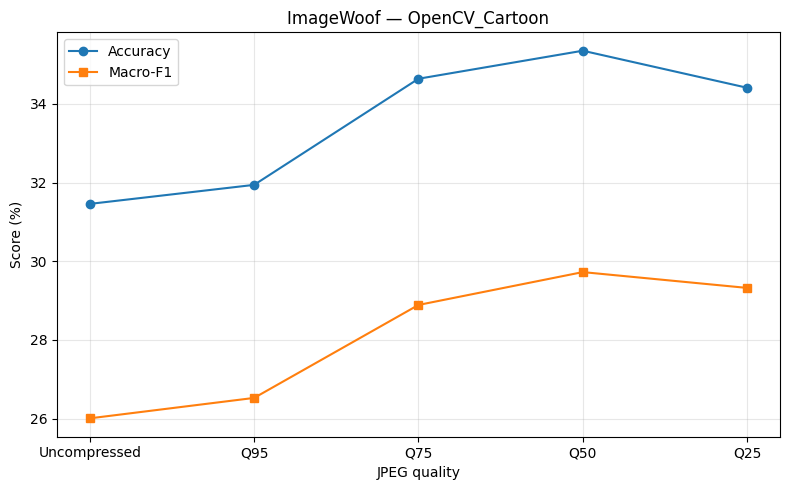

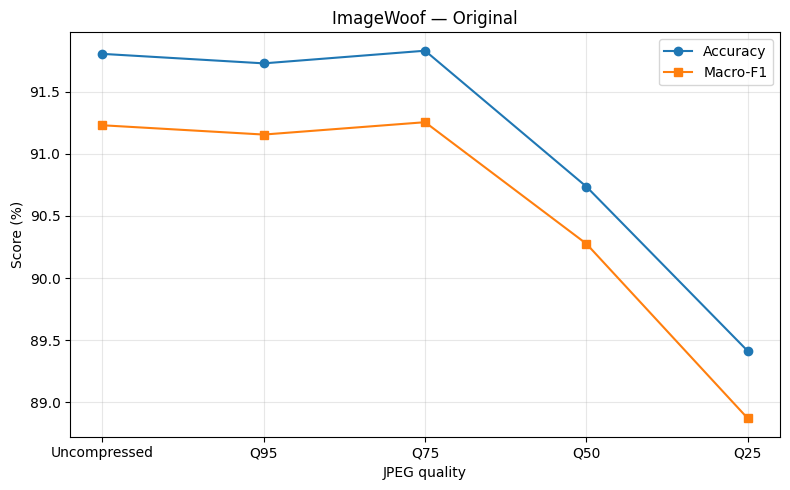

All outputs saved in: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External


In [6]:

import matplotlib.pyplot as plt

plot_df = summary.copy()
plot_df["quality_order"] = plot_df["jpeg_quality"].map({
    "Uncompressed": 0, "Q95": 1, "Q75": 2, "Q50": 3, "Q25": 4
})
plot_df = plot_df.sort_values("quality_order")

for appearance in plot_df["appearance"].unique():
    subset = plot_df[plot_df["appearance"] == appearance]

    plt.figure(figsize=(8, 5))
    plt.plot(
        subset["jpeg_quality"], subset["accuracy"] * 100,
        marker="o", label="Accuracy"
    )
    plt.plot(
        subset["jpeg_quality"], subset["macro_f1"] * 100,
        marker="s", label="Macro-F1"
    )
    plt.xlabel("JPEG quality")
    plt.ylabel("Score (%)")
    plt.title(f"ImageWoof — {appearance}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    safe_name = appearance.lower()
    plt.savefig(
        os.path.join(OUT_DIR, f"{safe_name}_metrics.png"),
        dpi=200
    )
    plt.show()

print("All outputs saved in:", OUT_DIR)


In [7]:

from google.colab import drive
drive.mount("/content/drive")

import os
import json
import zipfile
import pandas as pd
from datetime import datetime

OUT_DIR = "/content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External"

os.makedirs(OUT_DIR, exist_ok=True)

expected_files = [
    "imagewoof_resnet18.pth",
    "training_history.csv",
    "imagewoof_predictions.csv",
    "imagewoof_metrics.csv",
    "class_mapping.json",
]

print("IMAGEWOOF OUTPUT VERIFICATION")
print("=" * 60)

inventory = []

for filename in expected_files:
    path = os.path.join(OUT_DIR, filename)
    exists = os.path.isfile(path)
    size_mb = round(os.path.getsize(path) / (1024**2), 2) if exists else None

    inventory.append({
        "file": filename,
        "exists": exists,
        "size_MB": size_mb
    })

    print(f"{'FOUND' if exists else 'MISSING':8} | {filename}"
          + (f" | {size_mb} MB" if exists else ""))

# Include all other outputs, including generated plots.
for root, dirs, files in os.walk(OUT_DIR):
    for filename in files:
        path = os.path.join(root, filename)
        if filename not in expected_files and not filename.endswith(".zip"):
            inventory.append({
                "file": os.path.relpath(path, OUT_DIR),
                "exists": True,
                "size_MB": round(os.path.getsize(path) / (1024**2), 2)
            })

inventory_path = os.path.join(OUT_DIR, "file_inventory.csv")
pd.DataFrame(inventory).to_csv(inventory_path, index=False)

# Save experiment metadata.
metadata = {
    "dataset": "ImageWoof 320px",
    "model": "ResNet18",
    "seed": 42,
    "training_epochs": 5,
    "evaluation_conditions": [
        "Original", "OpenCV_Cartoon",
        "JPEG uncompressed", "JPEG Q95", "JPEG Q75",
        "JPEG Q50", "JPEG Q25"
    ],
    "verification_time": datetime.now().isoformat(),
    "output_directory": OUT_DIR
}

with open(os.path.join(OUT_DIR, "experiment_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# Create a ZIP backup, excluding the ZIP itself.
zip_path = os.path.join(
    "/content/drive/MyDrive/CartoonizationResearchBackup",
    "ImageWoof_External_backup.zip"
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(OUT_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            if os.path.abspath(path) != os.path.abspath(zip_path):
                arcname = os.path.relpath(path, os.path.dirname(OUT_DIR))
                zf.write(path, arcname)

print("\nInventory saved:", inventory_path)
print("ZIP backup:", zip_path)
print("\nMissing expected files:",
      [x["file"] for x in inventory
       if x["file"] in expected_files and not x["exists"]])

# Display metrics if present.
metrics_path = os.path.join(OUT_DIR, "imagewoof_metrics.csv")
if os.path.isfile(metrics_path):
    print("\nSAVED EVALUATION METRICS")
    display(pd.read_csv(metrics_path))
else:
    print("\nWARNING: Metrics CSV is missing. Check the evaluation cell output.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IMAGEWOOF OUTPUT VERIFICATION
FOUND    | imagewoof_resnet18.pth | 42.73 MB
FOUND    | training_history.csv | 0.0 MB
FOUND    | imagewoof_predictions.csv | 3.68 MB
FOUND    | imagewoof_metrics.csv | 0.0 MB
FOUND    | class_mapping.json | 0.0 MB

Inventory saved: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External/file_inventory.csv
ZIP backup: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External_backup.zip

Missing expected files: []

SAVED EVALUATION METRICS


,appearance,jpeg_quality,n,accuracy,macro_f1,balanced_accuracy
0,OpenCV_Cartoon,Q25,3929.0,0.344108,0.293225,0.347047
1,OpenCV_Cartoon,Q50,3929.0,0.353525,0.297245,0.351201
2,OpenCV_Cartoon,Q75,3929.0,0.346399,0.288893,0.342865
3,OpenCV_Cartoon,Q95,3929.0,0.319420,0.265260,0.314982
4,OpenCV_Cartoon,Uncompressed,3929.0,0.314584,0.260068,0.309682
5,Original,Q25,3929.0,0.894121,0.888701,0.890850
6,Original,Q50,3929.0,0.907356,0.902755,0.902136
7,Original,Q75,3929.0,0.918300,0.912545,0.911847
8,Original,Q95,3929.0,0.917282,0.911549,0.910867
9,Original,Uncompressed,3929.0,0.918045,0.912297,0.911597


In [8]:

import os
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

OUT_DIR = "/content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External"
df = pd.read_csv(os.path.join(OUT_DIR, "imagewoof_predictions.csv"))

df["correct"] = (
    df["true_label"] == df["predicted_label"]
).astype(int)

rng = np.random.default_rng(42)
qualities = ["Uncompressed", "Q95", "Q75", "Q50", "Q25"]
results = []

for quality in qualities:
    sub = df[df["jpeg_quality"] == quality]
    wide = sub.pivot(
        index="image_index",
        columns="appearance",
        values="correct"
    ).dropna(subset=["Original", "OpenCV_Cartoon"])

    orig = wide["Original"].to_numpy(dtype=int)
    cartoon = wide["OpenCV_Cartoon"].to_numpy(dtype=int)
    diff = orig - cartoon
    n = len(diff)

    boot = np.array([
        diff[rng.integers(0, n, size=n)].mean()
        for _ in range(5000)
    ])
    lo, hi = np.quantile(boot, [0.025, 0.975])

    # Paired McNemar exact test
    b = int(((orig == 1) & (cartoon == 0)).sum())
    c = int(((orig == 0) & (cartoon == 1)).sum())
    both_wrong = int(((orig == 0) & (cartoon == 0)).sum())
    both_correct = int(((orig == 1) & (cartoon == 1)).sum())

    test = mcnemar(
        [[both_wrong, c], [b, both_correct]],
        exact=True
    )

    results.append({
        "jpeg_quality": quality,
        "n_images": n,
        "original_accuracy": orig.mean(),
        "cartoon_accuracy": cartoon.mean(),
        "accuracy_drop_pp": diff.mean() * 100,
        "ci95_lower_pp": lo * 100,
        "ci95_upper_pp": hi * 100,
        "mcnemar_p": test.pvalue
    })

stats_df = pd.DataFrame(results)
stats_df["mcnemar_p_holm"] = multipletests(
    stats_df["mcnemar_p"], method="holm"
)[1]

path = os.path.join(
    OUT_DIR, "imagewoof_paired_statistics.csv"
)
stats_df.to_csv(path, index=False)

print(stats_df.round(6).to_string(index=False))
print("\nSaved to:", path)


jpeg_quality  n_images  original_accuracy  cartoon_accuracy  accuracy_drop_pp  ci95_lower_pp  ci95_upper_pp  mcnemar_p  mcnemar_p_holm
Uncompressed      3929           0.918045          0.314584         60.346144      58.768134      61.949605        0.0             0.0
         Q95      3929           0.917282          0.319420         59.786205      58.208195      61.415118        0.0             0.0
         Q75      3929           0.918300          0.346399         57.190125      55.561212      58.819038        0.0             0.0
         Q50      3929           0.907356          0.353525         55.383049      53.754136      57.037414        0.0             0.0
         Q25      3929           0.894121          0.344108         55.001273      53.346908      56.579919        0.0             0.0

Saved to: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External/imagewoof_paired_statistics.csv


In [9]:

import os
import pandas as pd

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
IMAGEWOOF_DIR = os.path.join(ROOT, "ImageWoof_External")

# 1. Locate existing CSV files in the research backup.
print("=== EXISTING RESEARCH CSV FILES ===")

csv_files = []
for folder, dirs, files in os.walk(ROOT):
    # Skip unnecessary hidden/system folders.
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for name in files:
        if name.lower().endswith(".csv"):
            path = os.path.join(folder, name)
            csv_files.append(path)

for path in sorted(csv_files):
    try:
        df = pd.read_csv(path, nrows=5)
        print(f"\nFile: {os.path.relpath(path, ROOT)}")
        print("Columns:", list(df.columns))
    except Exception as e:
        print(f"\nCould not inspect {path}: {e}")

# 2. Display the verified ImageWoof summary.
metrics_path = os.path.join(
    IMAGEWOOF_DIR, "imagewoof_metrics.csv"
)
stats_path = os.path.join(
    IMAGEWOOF_DIR, "imagewoof_paired_statistics.csv"
)

if os.path.exists(metrics_path):
    print("\n=== IMAGEWOOF METRICS ===")
    print(pd.read_csv(metrics_path).to_string(index=False))
else:
    print("\nWARNING: ImageWoof metrics CSV not found.")

if os.path.exists(stats_path):
    print("\n=== IMAGEWOOF PAIRED STATISTICS ===")
    print(pd.read_csv(stats_path).to_string(index=False))
else:
    print("\nWARNING: Paired-statistics CSV not found.")


=== EXISTING RESEARCH CSV FILES ===

Could not inspect /content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project/logs/animeganv2_paprika_500_failures.csv: No columns to parse from file

File: Advanced_Project/logs/opencv_500_failures.csv
Columns: ['image_id', 'reason']

Could not inspect /content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project/logs/opencv_500_jpeg_failures.csv: No columns to parse from file

Could not inspect /content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project/logs/opencv_500_visual_quality_failures.csv: No columns to parse from file

File: Advanced_Project/logs/resnet18_jpeg_augmented_history.csv
Columns: ['model', 'epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'seconds']

File: Advanced_Project/logs/resnet18_standard_history.csv
Columns: ['model', 'epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'seconds']

File: Advanced_Project/manifests/animeganv2_paprika_500_manifest.csv
Columns: ['


Loaded: Advanced_Project/metrics/clean_test_summary.csv
Rows: 2 | Columns: ['model', 'n_test', 'top1_accuracy', 'balanced_accuracy', 'macro_f1']

Loaded: Advanced_Project/metrics/jpeg_robustness_summary.csv
Rows: 8 | Columns: ['model', 'quality', 'n_images', 'top1_accuracy', 'balanced_accuracy', 'macro_f1']

Loaded: Advanced_Project/metrics/opencv_balanced_pilot_summary.csv
Rows: 2 | Columns: ['model', 'n_images', 'top1_accuracy', 'balanced_accuracy', 'macro_f1']

Loaded: Advanced_Project/metrics/opencv_500_jpeg_summary.csv
Rows: 8 | Columns: ['model', 'method', 'quality', 'n_images', 'top1_accuracy', 'balanced_accuracy', 'macro_f1']

Loaded: ImageWoof_External/imagewoof_metrics.csv
Rows: 10 | Columns: ['appearance', 'jpeg_quality', 'n', 'accuracy', 'macro_f1', 'balanced_accuracy']

=== COMBINED RESULTS ===
   dataset                 experiment_scope                   model                    condition   jpeg_quality  n_images  accuracy  macro_f1  balanced_accuracy                    

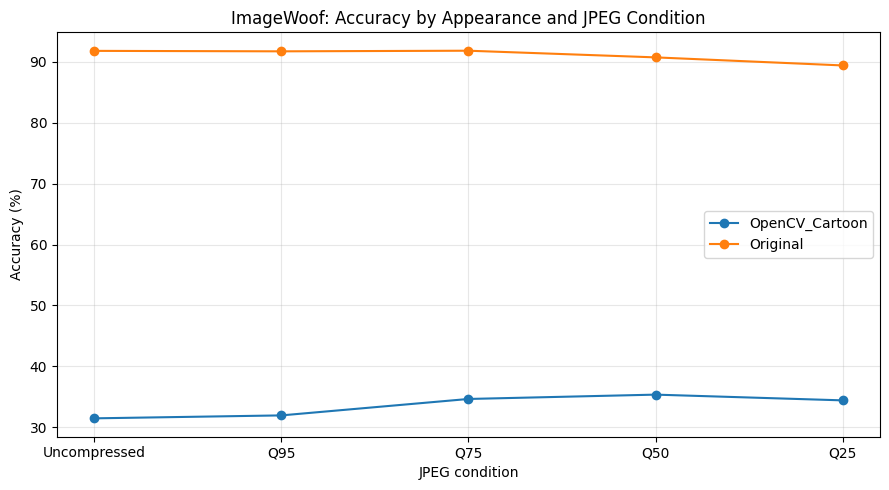

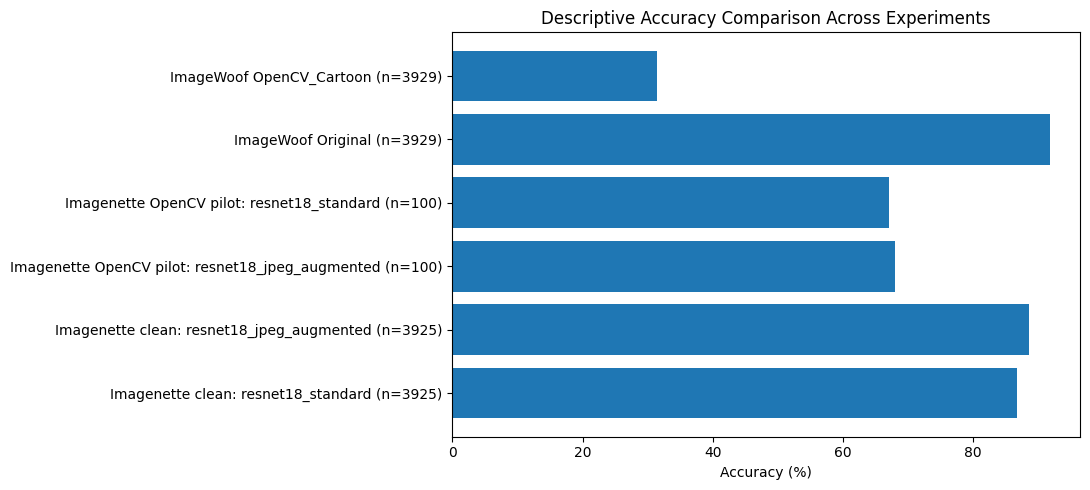


Analysis folder: /content/drive/MyDrive/CartoonizationResearchBackup/Combined_Research_Analysis
Files created:
 - combined_results_all_experiments.csv
 - descriptive_accuracy_comparison.png
 - imagenette_results.csv
 - imagewoof_accuracy_comparison.png
 - imagewoof_results.csv


In [10]:

import os
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
ADV = os.path.join(ROOT, "Advanced_Project")
WOOF = os.path.join(ROOT, "ImageWoof_External")
OUT = os.path.join(ROOT, "Combined_Research_Analysis")
os.makedirs(OUT, exist_ok=True)

all_rows = []

def add_rows(path, dataset, experiment, condition, quality_col=None):
    if not os.path.isfile(path):
        print("NOT FOUND:", path)
        return

    df = pd.read_csv(path)
    print(f"\nLoaded: {os.path.relpath(path, ROOT)}")
    print("Rows:", len(df), "| Columns:", list(df.columns))

    for _, r in df.iterrows():
        model = r.get("model", "ResNet18")
        n = r.get("n_images", r.get("n_test", r.get("n", None)))

        acc = r.get("top1_accuracy", r.get("accuracy", None))
        macro = r.get("macro_f1", None)
        balanced = r.get("balanced_accuracy", None)

        quality = r.get(quality_col, "Not applicable") if quality_col else "Not applicable"
        row_condition = condition

        # Some summary files contain an appearance or method column.
        if "appearance" in df.columns:
            row_condition = r["appearance"]
        elif "method" in df.columns:
            row_condition = str(r["method"]) + " / " + condition

        all_rows.append({
            "dataset": dataset,
            "experiment_scope": experiment,
            "model": model,
            "condition": row_condition,
            "jpeg_quality": quality,
            "n_images": n,
            "accuracy": acc,
            "macro_f1": macro,
            "balanced_accuracy": balanced,
            "source_file": os.path.basename(path)
        })

# Imagenette: clean test
add_rows(
    os.path.join(ADV, "metrics", "clean_test_summary.csv"),
    "Imagenette", "Full clean test", "Original"
)

# Imagenette: JPEG robustness
add_rows(
    os.path.join(ADV, "metrics", "jpeg_robustness_summary.csv"),
    "Imagenette", "JPEG robustness experiment", "JPEG",
    quality_col="quality"
)

# Imagenette: balanced OpenCV pilot
add_rows(
    os.path.join(ADV, "metrics", "opencv_balanced_pilot_summary.csv"),
    "Imagenette", "Balanced OpenCV pilot", "OpenCV cartoon"
)

# Imagenette: 500-image OpenCV + JPEG experiment
add_rows(
    os.path.join(ADV, "metrics", "opencv_500_jpeg_summary.csv"),
    "Imagenette", "500-image OpenCV/JPEG experiment", "OpenCV/JPEG",
    quality_col="quality"
)

# ImageWoof: all appearance and JPEG conditions
add_rows(
    os.path.join(WOOF, "imagewoof_metrics.csv"),
    "ImageWoof", "External validation", "Appearance",
    quality_col="jpeg_quality"
)

combined = pd.DataFrame(all_rows)

combined_path = os.path.join(OUT, "combined_results_all_experiments.csv")
combined.to_csv(combined_path, index=False)

print("\n=== COMBINED RESULTS ===")
print(combined.to_string(index=False))
print("\nSaved:", combined_path)

# Separate, clearly labelled tables for interpretation.
if not combined.empty:
    combined[combined["dataset"] == "Imagenette"].to_csv(
        os.path.join(OUT, "imagenette_results.csv"), index=False
    )
    combined[combined["dataset"] == "ImageWoof"].to_csv(
        os.path.join(OUT, "imagewoof_results.csv"), index=False
    )

# Graph 1: ImageWoof accuracy by appearance and JPEG condition.
woof = pd.read_csv(os.path.join(WOOF, "imagewoof_metrics.csv"))
order = ["Uncompressed", "Q95", "Q75", "Q50", "Q25"]
woof["jpeg_quality"] = pd.Categorical(
    woof["jpeg_quality"], categories=order, ordered=True
)

plt.figure(figsize=(9, 5))
for appearance, group in woof.groupby("appearance"):
    group = group.sort_values("jpeg_quality")
    plt.plot(
        group["jpeg_quality"].astype(str),
        group["accuracy"] * 100,
        marker="o",
        label=appearance
    )

plt.xlabel("JPEG condition")
plt.ylabel("Accuracy (%)")
plt.title("ImageWoof: Accuracy by Appearance and JPEG Condition")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT, "imagewoof_accuracy_comparison.png"),
    dpi=200
)
plt.show()

# Graph 2: descriptive original vs cartoon comparison.
# The Imagenette OpenCV pilot is shown separately from its full clean test.
chart_rows = []

clean_path = os.path.join(ADV, "metrics", "clean_test_summary.csv")
pilot_path = os.path.join(ADV, "metrics", "opencv_balanced_pilot_summary.csv")

if os.path.isfile(clean_path):
    clean = pd.read_csv(clean_path)
    for _, r in clean.iterrows():
        chart_rows.append({
            "label": f"Imagenette clean: {r['model']} (n={int(r['n_test'])})",
            "accuracy": r["top1_accuracy"] * 100
        })

if os.path.isfile(pilot_path):
    pilot = pd.read_csv(pilot_path)
    for _, r in pilot.iterrows():
        chart_rows.append({
            "label": f"Imagenette OpenCV pilot: {r['model']} (n={int(r['n_images'])})",
            "accuracy": r["top1_accuracy"] * 100
        })

for appearance in ["Original", "OpenCV_Cartoon"]:
    subset = woof[
        (woof["appearance"] == appearance) &
        (woof["jpeg_quality"].astype(str) == "Uncompressed")
    ]
    for _, r in subset.iterrows():
        chart_rows.append({
            "label": f"ImageWoof {appearance} (n={int(r['n'])})",
            "accuracy": r["accuracy"] * 100
        })

if chart_rows:
    chart = pd.DataFrame(chart_rows)
    plt.figure(figsize=(11, max(5, 0.5 * len(chart))))
    plt.barh(chart["label"], chart["accuracy"])
    plt.xlabel("Accuracy (%)")
    plt.title("Descriptive Accuracy Comparison Across Experiments")
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT, "descriptive_accuracy_comparison.png"),
        dpi=200
    )
    plt.show()

print("\nAnalysis folder:", OUT)
print("Files created:")
for f in sorted(os.listdir(OUT)):
    print(" -", f)


In [11]:

import os
import pandas as pd

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
ADV = os.path.join(ROOT, "Advanced_Project")
WOOF = os.path.join(ROOT, "ImageWoof_External")
OUT = os.path.join(ROOT, "Combined_Research_Analysis")

rows = []

# Full Imagenette clean test
clean = pd.read_csv(
    os.path.join(ADV, "metrics", "clean_test_summary.csv")
)
for _, r in clean.iterrows():
    rows.append({
        "dataset": "Imagenette",
        "experiment": "Full clean test",
        "model": r["model"],
        "condition": "Original",
        "jpeg_quality": "None",
        "n_images": int(r["n_test"]),
        "accuracy_pct": 100 * r["top1_accuracy"],
        "macro_f1_pct": 100 * r["macro_f1"],
        "balanced_accuracy_pct": 100 * r["balanced_accuracy"]
    })

# Smaller Imagenette OpenCV pilot
pilot = pd.read_csv(
    os.path.join(ADV, "metrics", "opencv_balanced_pilot_summary.csv")
)
for _, r in pilot.iterrows():
    rows.append({
        "dataset": "Imagenette",
        "experiment": "OpenCV pilot",
        "model": r["model"],
        "condition": "OpenCV cartoon",
        "jpeg_quality": "None",
        "n_images": int(r["n_images"]),
        "accuracy_pct": 100 * r["top1_accuracy"],
        "macro_f1_pct": 100 * r["macro_f1"],
        "balanced_accuracy_pct": 100 * r["balanced_accuracy"]
    })

# ImageWoof original and cartoon, uncompressed only
woof = pd.read_csv(os.path.join(WOOF, "imagewoof_metrics.csv"))
for appearance in ["Original", "OpenCV_Cartoon"]:
    r = woof[
        (woof["appearance"] == appearance) &
        (woof["jpeg_quality"] == "Uncompressed")
    ].iloc[0]

    rows.append({
        "dataset": "ImageWoof",
        "experiment": "External validation",
        "model": "ResNet18",
        "condition": appearance,
        "jpeg_quality": "None",
        "n_images": int(r["n"]),
        "accuracy_pct": 100 * r["accuracy"],
        "macro_f1_pct": 100 * r["macro_f1"],
        "balanced_accuracy_pct": 100 * r["balanced_accuracy"]
    })

paper_table = pd.DataFrame(rows)
paper_table = paper_table.round({
    "accuracy_pct": 2,
    "macro_f1_pct": 2,
    "balanced_accuracy_pct": 2
})

output_path = os.path.join(OUT, "main_paper_comparison.csv")
paper_table.to_csv(output_path, index=False)

print(paper_table.to_string(index=False))
print("\nSaved:", output_path)


   dataset          experiment                   model      condition jpeg_quality  n_images  accuracy_pct  macro_f1_pct  balanced_accuracy_pct
Imagenette     Full clean test       resnet18_standard       Original         None      3925         86.65         86.51                  86.84
Imagenette     Full clean test resnet18_jpeg_augmented       Original         None      3925         88.56         88.55                  88.50
Imagenette        OpenCV pilot resnet18_jpeg_augmented OpenCV cartoon         None       100         68.00         66.86                  68.00
Imagenette        OpenCV pilot       resnet18_standard OpenCV cartoon         None       100         67.00         67.12                  67.00
 ImageWoof External validation                ResNet18       Original         None      3929         91.80         91.23                  91.16
 ImageWoof External validation                ResNet18 OpenCV_Cartoon         None      3929         31.46         26.01                

In [12]:

import os
import pandas as pd
import numpy as np

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
WOOF = os.path.join(ROOT, "ImageWoof_External")

pred_path = os.path.join(WOOF, "imagewoof_predictions.csv")
mapping_path = os.path.join(WOOF, "class_mapping.json")

pred = pd.read_csv(pred_path)

print("Total prediction rows:", len(pred))
print("Unique images:", pred["image_index"].nunique())
print("Classes in true labels:", pred["true_label"].nunique())
print("Classes in predictions:", pred["predicted_label"].nunique())
print("Appearances:", sorted(pred["appearance"].unique()))
print("JPEG conditions:", sorted(pred["jpeg_quality"].unique()))

# Verify that each image has one row per appearance/quality condition.
print("\nRows per image:")
print(pred.groupby("image_index").size().value_counts().sort_index())

# Recalculate accuracy directly from prediction records.
pred["correct_recalculated"] = (
    pred["true_label"] == pred["predicted_label"]
).astype(int)

check = pred.groupby(
    ["appearance", "jpeg_quality"]
).agg(
    n=("correct_recalculated", "size"),
    accuracy=("correct_recalculated", "mean")
).reset_index()

print("\nRecalculated metrics:")
print(check.to_string(index=False))

print("\nSaved class mapping:")
with open(mapping_path) as f:
    print(f.read())


Total prediction rows: 39290
Unique images: 3929
Classes in true labels: 10
Classes in predictions: 10
Appearances: ['OpenCV_Cartoon', 'Original']
JPEG conditions: ['Q25', 'Q50', 'Q75', 'Q95', 'Uncompressed']

Rows per image:
10    3929
Name: count, dtype: int64

Recalculated metrics:
    appearance jpeg_quality    n  accuracy
OpenCV_Cartoon          Q25 3929  0.344108
OpenCV_Cartoon          Q50 3929  0.353525
OpenCV_Cartoon          Q75 3929  0.346399
OpenCV_Cartoon          Q95 3929  0.319420
OpenCV_Cartoon Uncompressed 3929  0.314584
      Original          Q25 3929  0.894121
      Original          Q50 3929  0.907356
      Original          Q75 3929  0.918300
      Original          Q95 3929  0.917282
      Original Uncompressed 3929  0.918045

Saved class mapping:
{
  "n02086240": 0,
  "n02087394": 1,
  "n02088364": 2,
  "n02089973": 3,
  "n02093754": 4,
  "n02096294": 5,
  "n02099601": 6,
  "n02105641": 7,
  "n02111889": 8,
  "n02115641": 9
}


In [13]:

import os
import json
import torch
from torchvision.datasets import ImageFolder

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
DATA_DIR = "/content/imagewoof2-320"
OUT_DIR = os.path.join(ROOT, "ImageWoof_External")

train_path = os.path.join(DATA_DIR, "train")
val_path = os.path.join(DATA_DIR, "val")
checkpoint_path = os.path.join(OUT_DIR, "imagewoof_resnet18.pth")
mapping_path = os.path.join(OUT_DIR, "class_mapping.json")

assert os.path.isdir(train_path), f"Missing: {train_path}"
assert os.path.isdir(val_path), f"Missing: {val_path}"
assert os.path.isfile(checkpoint_path), "Checkpoint not found in Drive"
assert os.path.isfile(mapping_path), "Class mapping not found in Drive"

train_ds = ImageFolder(train_path)
val_ds = ImageFolder(val_path)

with open(mapping_path) as f:
    saved_mapping = json.load(f)

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
checkpoint_mapping = checkpoint["class_to_idx"]

print("Train classes:", train_ds.classes)
print("Validation classes:", val_ds.classes)
print("Training class count:", len(train_ds.classes))
print("Validation class count:", len(val_ds.classes))

print("\nSaved JSON mapping matches training folders:",
      saved_mapping == train_ds.class_to_idx)

print("Checkpoint mapping matches training folders:",
      checkpoint_mapping == train_ds.class_to_idx)

print("Validation mapping matches training mapping:",
      val_ds.class_to_idx == train_ds.class_to_idx)

assert train_ds.class_to_idx == val_ds.class_to_idx
assert saved_mapping == train_ds.class_to_idx
assert checkpoint_mapping == train_ds.class_to_idx

print("\nPASS: Folder, JSON and checkpoint class mappings agree.")


Train classes: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Validation classes: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Training class count: 10
Validation class count: 10

Saved JSON mapping matches training folders: True
Checkpoint mapping matches training folders: True
Validation mapping matches training mapping: True

PASS: Folder, JSON and checkpoint class mappings agree.


=== IMAGENETTE FULL JPEG ROBUSTNESS ===
                  model  quality  n_images  accuracy_pct  balanced_accuracy_pct  macro_f1_pct
resnet18_jpeg_augmented       95      3925        88.484                 88.429        88.477
resnet18_jpeg_augmented       75      3925        88.535                 88.474        88.527
resnet18_jpeg_augmented       50      3925        88.153                 88.083        88.148
resnet18_jpeg_augmented       25      3925        87.720                 87.642        87.720
      resnet18_standard       95      3925        86.777                 86.965        86.626
      resnet18_standard       75      3925        86.777                 86.961        86.639
      resnet18_standard       50      3925        86.522                 86.723        86.353
      resnet18_standard       25      3925        86.166                 86.337        86.031

=== IMAGENETTE 500-IMAGE OPENCV/JPEG EXPERIMENT ===
         model         method  quality  n_images  accuracy_pc

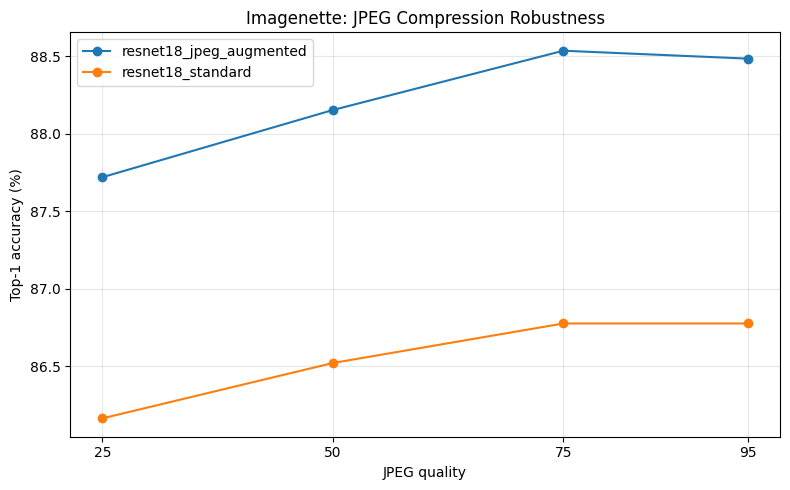

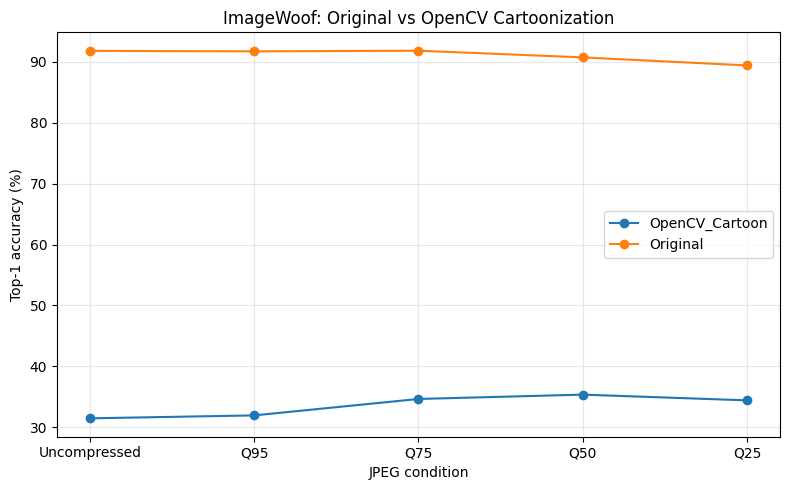


=== RESEARCH SUMMARY ===
                                            finding  value_pct                                                 scope
       Imagenette clean accuracy: standard ResNet18     86.650                                3925 clean test images
 Imagenette clean accuracy: JPEG-augmented ResNet18     88.561                                3925 clean test images
ImageWoof accuracy drop: original vs OpenCV cartoon     60.346 Percentage-point drop; 3,929 paired validation images

All tables and figures saved in:
/content/drive/MyDrive/CartoonizationResearchBackup/Combined_Research_Analysis

Files:
 - combined_results_all_experiments.csv
 - descriptive_accuracy_comparison.png
 - imagenette_full_jpeg_robustness_table.csv
 - imagenette_jpeg_robustness.png
 - imagenette_opencv_500_jpeg_table.csv
 - imagenette_results.csv
 - imagewoof_accuracy_comparison.png
 - imagewoof_appearance_jpeg.png
 - imagewoof_full_condition_table.csv
 - imagewoof_results.csv
 - main_paper_comparison.csv

In [14]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
ADV = os.path.join(ROOT, "Advanced_Project")
WOOF = os.path.join(ROOT, "ImageWoof_External")
OUT = os.path.join(ROOT, "Combined_Research_Analysis")
os.makedirs(OUT, exist_ok=True)

# 1. Full Imagenette JPEG robustness results
jpeg_path = os.path.join(
    ADV, "metrics", "jpeg_robustness_summary.csv"
)
jpeg = pd.read_csv(jpeg_path)

jpeg_table = jpeg.copy()
for col in ["top1_accuracy", "macro_f1", "balanced_accuracy"]:
    jpeg_table[col] = jpeg_table[col] * 100

jpeg_table = jpeg_table.rename(columns={
    "top1_accuracy": "accuracy_pct",
    "macro_f1": "macro_f1_pct",
    "balanced_accuracy": "balanced_accuracy_pct"
})

quality_order = [95, 75, 50, 25]
jpeg_table["quality_order"] = pd.to_numeric(jpeg_table["quality"])
jpeg_table = jpeg_table.sort_values(
    ["model", "quality_order"], ascending=[True, False]
)

jpeg_table.to_csv(
    os.path.join(OUT, "imagenette_full_jpeg_robustness_table.csv"),
    index=False
)

print("=== IMAGENETTE FULL JPEG ROBUSTNESS ===")
print(jpeg_table.drop(columns="quality_order").round(3).to_string(index=False))

# 2. Separate 500-image OpenCV/JPEG experiment
pilot_path = os.path.join(
    ADV, "metrics", "opencv_500_jpeg_summary.csv"
)
pilot = pd.read_csv(pilot_path)

pilot_table = pilot.copy()
for col in ["top1_accuracy", "macro_f1", "balanced_accuracy"]:
    if col in pilot_table.columns:
        pilot_table[col] = pilot_table[col] * 100

pilot_table = pilot_table.rename(columns={
    "top1_accuracy": "accuracy_pct",
    "macro_f1": "macro_f1_pct",
    "balanced_accuracy": "balanced_accuracy_pct"
})

pilot_table.to_csv(
    os.path.join(OUT, "imagenette_opencv_500_jpeg_table.csv"),
    index=False
)

print("\n=== IMAGENETTE 500-IMAGE OPENCV/JPEG EXPERIMENT ===")
print(pilot_table.round(3).to_string(index=False))

# 3. Complete ImageWoof condition table
woof = pd.read_csv(os.path.join(WOOF, "imagewoof_metrics.csv"))

woof_table = woof.copy()
for col in ["accuracy", "macro_f1", "balanced_accuracy"]:
    woof_table[col + "_pct"] = woof_table[col] * 100

woof_table.to_csv(
    os.path.join(OUT, "imagewoof_full_condition_table.csv"),
    index=False
)

print("\n=== IMAGEWOOF FULL CONDITION TABLE ===")
print(woof_table.round(3).to_string(index=False))

# 4. Graph: full Imagenette JPEG robustness
plt.figure(figsize=(8, 5))

for model_name, group in jpeg.groupby("model"):
    group = group.copy()
    group["quality_num"] = pd.to_numeric(group["quality"])
    group = group.sort_values("quality_num", ascending=False)

    plt.plot(
        group["quality_num"],
        group["top1_accuracy"] * 100,
        marker="o",
        label=model_name
    )

plt.xlabel("JPEG quality")
plt.ylabel("Top-1 accuracy (%)")
plt.title("Imagenette: JPEG Compression Robustness")
plt.xticks([25, 50, 75, 95])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT, "imagenette_jpeg_robustness.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# 5. Graph: ImageWoof appearance and JPEG conditions
quality_order = ["Uncompressed", "Q95", "Q75", "Q50", "Q25"]
woof["jpeg_quality"] = pd.Categorical(
    woof["jpeg_quality"],
    categories=quality_order,
    ordered=True
)

plt.figure(figsize=(8, 5))

for appearance, group in woof.groupby("appearance", observed=True):
    group = group.sort_values("jpeg_quality")
    plt.plot(
        group["jpeg_quality"].astype(str),
        group["accuracy"] * 100,
        marker="o",
        label=appearance
    )

plt.xlabel("JPEG condition")
plt.ylabel("Top-1 accuracy (%)")
plt.title("ImageWoof: Original vs OpenCV Cartoonization")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT, "imagewoof_appearance_jpeg.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# 6. Save a brief research summary from verified results
clean = pd.read_csv(
    os.path.join(ADV, "metrics", "clean_test_summary.csv")
)
stats = pd.read_csv(
    os.path.join(WOOF, "imagewoof_paired_statistics.csv")
)

standard = clean[clean["model"] == "resnet18_standard"].iloc[0]
augmented = clean[clean["model"] == "resnet18_jpeg_augmented"].iloc[0]
uncompressed = stats[stats["jpeg_quality"] == "Uncompressed"].iloc[0]

summary = pd.DataFrame([
    {
        "finding": "Imagenette clean accuracy: standard ResNet18",
        "value_pct": standard["top1_accuracy"] * 100,
        "scope": f"{int(standard['n_test'])} clean test images"
    },
    {
        "finding": "Imagenette clean accuracy: JPEG-augmented ResNet18",
        "value_pct": augmented["top1_accuracy"] * 100,
        "scope": f"{int(augmented['n_test'])} clean test images"
    },
    {
        "finding": "ImageWoof accuracy drop: original vs OpenCV cartoon",
        "value_pct": uncompressed["accuracy_drop_pp"],
        "scope": "Percentage-point drop; 3,929 paired validation images"
    }
])

summary.to_csv(
    os.path.join(OUT, "verified_research_summary.csv"),
    index=False
)

print("\n=== RESEARCH SUMMARY ===")
print(summary.round(3).to_string(index=False))

print("\nAll tables and figures saved in:")
print(OUT)
print("\nFiles:")
for filename in sorted(os.listdir(OUT)):
    print(" -", filename)


In [15]:

import os
import json
import pandas as pd
from torchvision.datasets import ImageFolder

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
DATA_DIR = "/content/imagewoof2-320"
OUT_DIR = os.path.join(ROOT, "ImageWoof_External")

pred_path = os.path.join(OUT_DIR, "imagewoof_predictions.csv")
mapping_path = os.path.join(OUT_DIR, "class_mapping.json")

val_path = os.path.join(DATA_DIR, "val")
val_ds = ImageFolder(val_path)
pred = pd.read_csv(pred_path)

# Build the expected validation-image index.
expected = []
for idx, (path, label) in enumerate(val_ds.samples):
    expected.append({
        "image_index": idx,
        "relative_path_expected": os.path.relpath(path, val_path),
        "true_label_expected": label
    })

expected = pd.DataFrame(expected)

# Verify paths and labels against the actual validation folder.
unique_images = pred[
    ["image_index", "relative_path", "true_label"]
].drop_duplicates()

joined = expected.merge(
    unique_images,
    on="image_index",
    how="outer",
    indicator=True
)

path_mismatches = (
    joined["relative_path_expected"] != joined["relative_path"]
).fillna(True).sum()

label_mismatches = (
    joined["true_label_expected"] != joined["true_label"]
).fillna(True).sum()

# Check expected appearance/quality combinations.
expected_conditions = {
    (a, q)
    for a in ["Original", "OpenCV_Cartoon"]
    for q in ["Uncompressed", "Q95", "Q75", "Q50", "Q25"]
}

condition_counts = pred.groupby("image_index").apply(
    lambda g: len(set(zip(g["appearance"], g["jpeg_quality"])))
)

# Check duplicates and correctness flags.
duplicate_rows = pred.duplicated(
    ["image_index", "appearance", "jpeg_quality"]
).sum()

correct_mismatches = (
    pred["correct"].astype(int) !=
    (pred["true_label"] == pred["predicted_label"]).astype(int)
).sum()

condition_mismatches = 0
for _, group in pred.groupby("image_index"):
    actual = set(zip(group["appearance"], group["jpeg_quality"]))
    if actual != expected_conditions:
        condition_mismatches += 1

report = {
    "validation_images": len(val_ds),
    "prediction_rows": len(pred),
    "image_index_mapping_errors": int((joined["_merge"] != "both").sum()),
    "relative_path_mismatches": int(path_mismatches),
    "true_label_mismatches": int(label_mismatches),
    "images_missing_or_with_wrong_conditions": int(condition_mismatches),
    "duplicate_image_condition_rows": int(duplicate_rows),
    "correct_flag_mismatches": int(correct_mismatches),
}

report_path = os.path.join(OUT_DIR, "final_prediction_audit.json")
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("FINAL IMAGEWOOF PREDICTION AUDIT")
for key, value in report.items():
    print(f"{key}: {value}")

passed = all(
    report[k] == 0 for k in [
        "image_index_mapping_errors",
        "relative_path_mismatches",
        "true_label_mismatches",
        "images_missing_or_with_wrong_conditions",
        "duplicate_image_condition_rows",
        "correct_flag_mismatches"
    ]
)

print("\nAUDIT STATUS:", "PASS" if passed else "CHECK REQUIRED")
print("Audit report saved to:", report_path)


/tmp/ipykernel_817/2677205698.py:55: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  condition_counts = pred.groupby("image_index").apply(


FINAL IMAGEWOOF PREDICTION AUDIT
validation_images: 3929
prediction_rows: 39290
image_index_mapping_errors: 0
relative_path_mismatches: 0
true_label_mismatches: 0
images_missing_or_with_wrong_conditions: 0
duplicate_image_condition_rows: 0
correct_flag_mismatches: 0

AUDIT STATUS: PASS
Audit report saved to: /content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External/final_prediction_audit.json


In [16]:

!pip -q install python-docx

from google.colab import drive, files
drive.mount("/content/drive")

import os, re
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

ROOT = "/content/drive/MyDrive/CartoonizationResearchBackup"
os.makedirs(ROOT, exist_ok=True)

filename = "Cartoonization_JPEG_Robustness-original.docx"
candidates = [
    os.path.join(ROOT, filename),
    os.path.join("/content/drive/MyDrive", filename)
]

source_path = next((p for p in candidates if os.path.isfile(p)), None)

if source_path is None:
    print("Upload your original Cartoonization_JPEG_Robustness-original.docx")
    uploaded = files.upload()
    matches = [name for name in uploaded if name.lower().endswith(".docx")]
    if not matches:
        raise FileNotFoundError("Please upload the original .docx manuscript.")
    source_path = os.path.abspath(matches[0])

doc = Document(source_path)

def find_paragraph(pattern):
    rx = re.compile(pattern, re.IGNORECASE)
    for p in doc.paragraphs:
        if rx.search(p.text.strip()):
            return p
    return None

def insert_paragraph_before(anchor, text, style=None):
    return anchor.insert_paragraph_before(text, style=style)

def insert_table_before(anchor, headers, rows):
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = "Table Grid"

    for i, value in enumerate(headers):
        table.rows[0].cells[i].text = str(value)

    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)

    anchor._p.addprevious(table._tbl)
    return table

# ---------------------------------------------------------
# 1. Update abstract with the separate ImageWoof benchmark
# ---------------------------------------------------------
abstract = find_paragraph(r"^Abstract\s*[—–-]")
if abstract is None:
    abstract = find_paragraph(r"^Abstract.*cartoonization")

if abstract is not None:
    abstract.text = (
        "Abstract—This study evaluates how image cartoonization and JPEG "
        "compression affect semantic image classification through a matched-image "
        "Imagenette-320 benchmark and a separate ImageWoof-320 benchmark. The "
        "Imagenette study evaluates 3,925 matched source images across original, "
        "OpenCV, AnimeGANv2, and Stable Diffusion v1.5 appearances, five JPEG "
        "conditions, and two ResNet18 checkpoints, yielding 157,000 prediction "
        "records. Standard ResNet18 achieves 86.65% accuracy on original images, "
        "58.78% on OpenCV cartoons, 76.92% on AnimeGANv2, and 79.77% on Stable "
        "Diffusion outputs. JPEG augmentation raises original-image accuracy to "
        "88.56%, but does not improve recognition of the tested cartoon domains. "
        "A separate ImageWoof experiment trains a ten-class ResNet18 and evaluates "
        "3,929 validation images under original and OpenCV-cartoon appearances "
        "with five JPEG conditions. Accuracy on original images without additional "
        "JPEG recompression is 91.80%, compared with 31.46% for OpenCV cartoons, "
        "a 60.35-percentage-point difference (paired-bootstrap 95% CI: "
        "58.77–61.95 percentage points). Across the five ImageWoof conditions, "
        "the original-versus-cartoon accuracy difference ranges from 55.00 to "
        "60.35 percentage points. ImageWoof is a separate benchmark using a "
        "separately trained classifier, not a zero-shot transfer test of the "
        "Imagenette-trained models. Findings are specific to the tested datasets, "
        "checkpoints, and transformations and do not establish a universal ranking "
        "or a causal feature-level explanation."
    )
else:
    print("WARNING: Abstract paragraph not found; update it manually after review.")

# ---------------------------------------------------------
# 2. Add ImageWoof methodology before the Results section
# ---------------------------------------------------------
results_anchor = find_paragraph(r"^4\.?\s+Results\b")
if results_anchor is None:
    results_anchor = find_paragraph(r"^4\.1\b")

if results_anchor is None:
    raise ValueError(
        "Could not find the Results heading. Inspect the manuscript headings "
        "before continuing; no output document has been saved."
    )

insert_paragraph_before(
    results_anchor,
    "3.4 Separate ImageWoof External-Benchmark Protocol",
    "Heading 2"
)
insert_paragraph_before(
    results_anchor,
    "ImageWoof-320 was evaluated as a separate benchmark rather than as a "
    "zero-shot test of the Imagenette-trained checkpoints. The dataset contains "
    "9,025 training images and 3,929 official validation images across ten "
    "dog-breed classes. A new ResNet18 initialized with ImageNet-pretrained "
    "weights was configured with a ten-output classification layer and trained "
    "for five epochs using AdamW (learning rate 1 × 10⁻⁴, weight decay 1 × 10⁻⁴, "
    "batch size 64, random seed 42). Training preprocessing used random-resized "
    "crops and horizontal flips. Evaluation preprocessing resized images to "
    "256 pixels, applied a 224-pixel center crop, and used ImageNet mean and "
    "standard-deviation normalization."
)
insert_paragraph_before(
    results_anchor,
    "The ImageWoof evaluation considered two appearances—original and OpenCV "
    "cartoonized—and five compression conditions: no additional JPEG "
    "recompression, Q95, Q75, Q50, and Q25. This produced 3,929 × 2 × 5 = "
    "39,290 prediction records. The official validation partition was evaluated "
    "after training; no separate third test partition or repeated-seed experiment "
    "is reported. ImageWoof results are therefore interpreted independently "
    "from the Imagenette benchmark."
)

# ---------------------------------------------------------
# 3. Add ImageWoof results before the Discussion section
# ---------------------------------------------------------
discussion_anchor = find_paragraph(r"^5\.?\s+Discussion\b")
if discussion_anchor is None:
    raise ValueError(
        "Could not find the Discussion heading. Inspect the manuscript headings "
        "before continuing; no output document has been saved."
    )

insert_paragraph_before(
    discussion_anchor,
    "4.8 ImageWoof External-Benchmark Results",
    "Heading 2"
)
insert_paragraph_before(
    discussion_anchor,
    "The ImageWoof classifier achieved 91.80% Top-1 accuracy on original images "
    "without additional JPEG recompression and 31.46% on OpenCV-cartoonized "
    "images under the same condition. The paired accuracy difference was "
    "60.35 percentage points (95% paired-bootstrap CI: 58.77–61.95). Across "
    "the five compression conditions, the original-versus-cartoon accuracy "
    "difference ranged from 55.00 to 60.35 percentage points. Macro-F1 was "
    "91.23% for original images without additional recompression and 26.01% "
    "for OpenCV cartoons. These results show a large recognition difference "
    "for this independently trained classifier and dataset; they do not show "
    "that the Imagenette-trained checkpoints transfer directly to ImageWoof."
)
insert_paragraph_before(
    discussion_anchor,
    "Table 12. ImageWoof accuracy and paired accuracy differences across JPEG conditions",
    "Caption"
)

headers = [
    "JPEG condition",
    "Original accuracy (%)",
    "OpenCV accuracy (%)",
    "Accuracy drop (pp)",
    "Paired 95% CI (pp)"
]
rows = [
    ["No additional recompression", "91.80", "31.46", "60.35", "58.77–61.95"],
    ["Q95", "91.73", "31.94", "59.79", "58.21–61.42"],
    ["Q75", "91.83", "34.64", "57.19", "55.56–58.82"],
    ["Q50", "90.74", "35.35", "55.38", "53.75–57.04"],
    ["Q25", "89.41", "34.41", "55.00", "53.35–56.58"]
]
insert_table_before(discussion_anchor, headers, rows)

insert_paragraph_before(
    discussion_anchor,
    "Note: Accuracy drop is original accuracy minus OpenCV-cartoon accuracy in "
    "percentage points. Confidence intervals use paired bootstrap resampling "
    "over source-image identities (5,000 replicates). Exact McNemar tests with "
    "Holm correction were significant for all five comparisons (adjusted p < "
    "0.001). The exported statistical CSV displays 0.0 for these p-values due "
    "to numerical underflow; this is not interpreted as a literal probability of zero."
)

# ---------------------------------------------------------
# 4. Update the limitation about the former ImageWoof pilot
# ---------------------------------------------------------
for p in doc.paragraphs:
    text = p.text
    if "The stimulation of ImageWoof" in text or (
        "feasibility experiment using combined data" in text
    ):
        p.text = (
            "The earlier ViT-B/16 experiments used different decision protocols "
            "and smaller pilot samples and should remain separate from the main "
            "ResNet18 benchmark. The additional ImageWoof experiment reported "
            "here uses a separately trained ResNet18 and is not a zero-shot "
            "evaluation of the Imagenette-trained checkpoint. It evaluates "
            "original and OpenCV-cartoon appearances only; AnimeGANv2 and Stable "
            "Diffusion have not been evaluated in this ImageWoof experiment. "
            "The ImageWoof results use one training seed and one five-epoch "
            "training run, so between-seed variability is not measured."
        )

future_anchor = find_paragraph(r"^5\.4\s+Future Work\b")
if future_anchor is not None:
    insert_paragraph_before(
        future_anchor,
        "The ImageWoof extension broadens the evaluation to a second dataset, "
        "but it remains limited to one separately trained ResNet18 checkpoint, "
        "one training seed, and OpenCV cartoonization. Although the saved class "
        "mapping, image paths, prediction counts, and correctness flags passed "
        "consistency checks, these checks do not independently establish the "
        "visual correctness of every transformation or exclude all preprocessing "
        "issues. Future work should evaluate the other cartoonization pipelines "
        "on ImageWoof, repeat training across multiple seeds, and independently "
        "verify transformation outputs and preprocessing."
    )

# ---------------------------------------------------------
# 5. Update the conclusion's final summary paragraph
# ---------------------------------------------------------
for p in doc.paragraphs:
    if p.text.strip().startswith(
        "Using data from 3,925 Imagenette photographs"
    ):
        p.text = (
            "The main matched Imagenette study evaluates 3,925 source images "
            "across four appearance conditions, five JPEG conditions, and two "
            "ResNet18 checkpoints. Standard ResNet18 reaches 86.65% accuracy on "
            "original photographs, compared with 58.78% for OpenCV, 76.92% for "
            "AnimeGANv2, and 79.77% for Stable Diffusion. The JPEG-augmented "
            "checkpoint achieves 88.56% on original photographs but lower "
            "recognition accuracy than the standard checkpoint on the tested "
            "cartoon domains. The separate ImageWoof benchmark adds evidence "
            "from 3,929 validation images evaluated with a newly trained "
            "ten-class ResNet18: accuracy is 91.80% on original images and "
            "31.46% on OpenCV cartoons without additional JPEG recompression, "
            "a 60.35-percentage-point difference. Because the ImageWoof model "
            "was trained separately, this is a second-dataset benchmark rather "
            "than zero-shot cross-dataset transfer. Taken together, the results "
            "show that recognition accuracy depends strongly on image appearance "
            "and that JPEG effects are not uniformly monotonic. Further work "
            "should test additional cartoonizers on ImageWoof, repeat training "
            "across seeds, and verify the findings across more datasets and "
            "classifier architectures."
        )
        break

# ---------------------------------------------------------
# 6. Save a new file; never overwrite the original
# ---------------------------------------------------------
output_path = os.path.join(
    ROOT, "Cartoonization_JPEG_Robustness_UPDATED_ImageWoof.docx"
)
doc.save(output_path)

# Reopen to verify the new document can be read.
check = Document(output_path)
all_text = "\n".join(p.text for p in check.paragraphs)

print("\nUPDATED MANUSCRIPT SAVED")
print(output_path)
print("Paragraphs:", len(check.paragraphs))
print("Tables:", len(check.tables))
print("ImageWoof methodology present:",
      "3.4 Separate ImageWoof External-Benchmark Protocol" in all_text)
print("ImageWoof results present:",
      "4.8 ImageWoof External-Benchmark Results" in all_text)
print("Updated conclusion present:",
      "The separate ImageWoof benchmark adds evidence" in all_text)
print("\nOriginal manuscript was not overwritten.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Upload your original Cartoonization_JPEG_Robustness-original.docx


Saving cartoon with convx.docx to cartoon with convx.docx


ValueError: Could not find the Discussion heading. Inspect the manuscript headings before continuing; no output document has been saved.

In [1]:

import os

source_path = (
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Cartoonization_JPEG_Robustness-original.docx"
)

if os.path.exists(source_path):
    print("Correct manuscript found:", source_path)
else:
    print("File not found at that location.")
    print("Please check the exact filename in Google Drive.")


File not found at that location.
Please check the exact filename in Google Drive.


In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

search_root = '/content/drive/MyDrive'
keywords = ('cartoon', 'robustness', 'convx', 'imagewoof')

print("Searching Google Drive for matching Word documents...\n")

matches = []

for root, dirs, files in os.walk(search_root):
    # Skip system folders to make the search faster
    dirs[:] = [d for d in dirs if d not in {
        '.ipynb_checkpoints', '.Trash'
    }]

    for filename in files:
        if filename.lower().endswith(('.docx', '.doc')):
            if any(word in filename.lower() for word in keywords):
                path = os.path.join(root, filename)
                matches.append(path)
                print(path)

if not matches:
    print("\nNo matching Word documents found in My Drive.")
    print("Check whether the file is in Shared with me or another Google account.")
else:
    print(f"\nFound {len(matches)} matching document(s).")

Mounted at /content/drive
Searching Google Drive for matching Word documents...

/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_Draft.docx
/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_MatchedResults_Draft.docx

Found 2 matching document(s).


In [3]:
import os
from datetime import datetime

folder = '/content/drive/MyDrive/CartoonizationResearchBackup'

files = [
    'Cartoonization_Research_Manuscript_Draft.docx',
    'Cartoonization_Research_Manuscript_MatchedResults_Draft.docx'
]

for name in files:
    path = os.path.join(folder, name)
    if os.path.exists(path):
        stat = os.stat(path)
        print(f'File: {name}')
        print(f'Size: {stat.st_size:,} bytes')
        print(f'Last modified: {datetime.fromtimestamp(stat.st_mtime)}')
        print('-' * 50)

File: Cartoonization_Research_Manuscript_Draft.docx
Size: 43,727 bytes
Last modified: 2026-10-15 08:30:24
--------------------------------------------------
File: Cartoonization_Research_Manuscript_MatchedResults_Draft.docx
Size: 44,202 bytes
Last modified: 2026-10-15 08:51:11
--------------------------------------------------


In [8]:
from docx import Document
import os

path = (
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Cartoonization_Research_Manuscript_MatchedResults_Draft.docx"
)

doc = Document(path)

print("MANUSCRIPT:", os.path.basename(path))
print("Paragraphs:", len(doc.paragraphs))
print("\n--- HEADINGS AND KEY SECTIONS ---")

for i, para in enumerate(doc.paragraphs):
    text = para.text.strip()
    if not text:
        continue

    style = para.style.name if para.style else ""

    if (
        "heading" in style.lower()
        or any(word in text.lower() for word in [
            "abstract", "introduction", "methodology",
            "result", "discussion", "conclusion",
            "limitation", "imagewoof", "convnext"
        ])
    ):
        print(f"[{i}] [{style}] {text[:250]}")

print("\n--- TABLE COUNT ---")
print(len(doc.tables))

MANUSCRIPT: Cartoonization_Research_Manuscript_MatchedResults_Draft.docx
Paragraphs: 90

--- HEADINGS AND KEY SECTIONS ---
[4] [Heading 1] Abstract
[5] [Normal] Image cartoonization transforms photographs into stylized images, but visual appeal alone does not establish whether transformed images retain information useful for machine recognition. This study compares three pipelines—OpenCV-based cartoonization
[7] [Heading 1] 1. Introduction
[10] [Normal] The study compares OpenCV cartoonization, pretrained AnimeGANv2, and a pretrained Stable Diffusion image-to-image pipeline using a fixed ResNet18 classifier. It evaluates clean images and four degradation conditions and examines recognition accuracy,
[11] [Heading 1] 2. Related Work
[12] [Heading 2] 2.1 Image-to-image translation and cartoonization
[15] [Heading 2] 2.2 Diffusion-based image synthesis
[17] [Heading 2] 2.3 Robustness and image-quality evaluation
[20] [Heading 2] 2.4 Recognition model and dataset
[22] [Heading 1] 3. Resear

In [6]:
!pip install -q python-docx

In [7]:
from docx import Document
import os

In [9]:
import os

root = "/content/drive/MyDrive/CartoonizationResearchBackup"

print("Word documents and research files:\n")

for folder, _, files in os.walk(root):
    for filename in files:
        if filename.lower().endswith((
            ".docx", ".doc", ".tex", ".md", ".pdf"
        )):
            print(os.path.join(folder, filename))

Word documents and research files:

/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Complete_Summary.pdf
/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_Draft.docx
/content/drive/MyDrive/CartoonizationResearchBackup/Updated_Literature_Review_Novelty_Audit.docx
/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_MatchedResults_Draft.docx
/content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_Final_Review_Copy.pdf


In [10]:
!pip install -q python-docx pypdf

import os
from docx import Document
from pypdf import PdfReader

folder = "/content/drive/MyDrive/CartoonizationResearchBackup"

files = [
    "Cartoonization_Research_Complete_Summary.pdf",
    "Cartoonization_Research_Manuscript_Draft.docx",
    "Cartoonization_Research_Manuscript_MatchedResults_Draft.docx",
    "Cartoonization_Research_Manuscript_Final_Review_Copy.pdf",
    "Updated_Literature_Review_Novelty_Audit.docx",
]

keywords = [
    "3,925", "3925", "3,929", "3929",
    "ImageWoof", "ConvNeXt", "157,000",
    "JPEG", "Imagenette", "ResNet18"
]

for filename in files:
    path = os.path.join(folder, filename)
    if not os.path.exists(path):
        print(f"\nMISSING: {filename}")
        continue

    if filename.lower().endswith(".docx"):
        doc = Document(path)
        content = "\n".join(p.text for p in doc.paragraphs)
        content += "\n" + "\n".join(
            cell.text for table in doc.tables
            for row in table.rows for cell in row.cells
        )
    else:
        reader = PdfReader(path)
        content = "\n".join(page.extract_text() or "" for page in reader.pages)

    print("\n" + "=" * 75)
    print(f"FILE: {filename}")
    print(f"Characters: {len(content):,}")

    for keyword in keywords:
        positions = []
        start = 0
        while True:
            pos = content.lower().find(keyword.lower(), start)
            if pos == -1:
                break
            positions.append(pos)
            start = pos + len(keyword)

        if positions:
            print(f"\n[{keyword}] found {len(positions)} time(s)")
            for pos in positions[:2]:
                snippet = content[max(0, pos-160):pos+260]
                print(" ", " ".join(snippet.split()))


FILE: Cartoonization_Research_Complete_Summary.pdf
Characters: 10,467

[JPEG] found 3 time(s)
  lts for this sample, not universal rankings. 4. Accuracy under selected degradation conditions Figure 3. Reported accuracy under Gaussian blur, Gaussian noise, JPEG compression, and low illumination. Cartoonization research summary — draft for supervisor review Page 3 Method Gaussian blur Gaussian noise* JPEG compression Low illumination Original 62.59% 72.33% 76.35% 75.18% OpenCV 11.89% 13.67% 17.91% 15.96% AnimeGA
  ssian noise, JPEG compression, and low illumination. Cartoonization research summary — draft for supervisor review Page 3 Method Gaussian blur Gaussian noise* JPEG compression Low illumination Original 62.59% 72.33% 76.35% 75.18% OpenCV 11.89% 13.67% 17.91% 15.96% AnimeGANv2 40.56% 61.00% 57.43% 48.23% Stable Diffusion 21.33% 24.24% 29.73% 20.21% Important limitation: The Gaussian-noise summary was not calculated us

[Imagenette] found 2 time(s)
  on, pretrained AnimeGANv2, an

In [12]:
import os

folders = [
    "/content/drive/MyDrive/CartoonizationResearchBackup/Combined_Research_Analysis",
    "/content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External",
]

for folder in folders:
    print(f"\n{'='*65}\n{folder}")
    if not os.path.isdir(folder):
        print("Folder not found")
        continue

    for name in sorted(os.listdir(folder)):
        print(name)


/content/drive/MyDrive/CartoonizationResearchBackup/Combined_Research_Analysis
combined_results_all_experiments.csv
descriptive_accuracy_comparison.png
imagenette_full_jpeg_robustness_table.csv
imagenette_jpeg_robustness.png
imagenette_opencv_500_jpeg_table.csv
imagenette_results.csv
imagewoof_accuracy_comparison.png
imagewoof_appearance_jpeg.png
imagewoof_full_condition_table.csv
imagewoof_results.csv
main_paper_comparison.csv
verified_research_summary.csv

/content/drive/MyDrive/CartoonizationResearchBackup/ImageWoof_External
class_mapping.json
experiment_metadata.json
file_inventory.csv
final_prediction_audit.json
imagewoof_metrics.csv
imagewoof_paired_statistics.csv
imagewoof_predictions.csv
imagewoof_resnet18.pth
opencv_cartoon_metrics.png
original_metrics.png
training_history.csv


In [13]:
import os
import pandas as pd

base = "/content/drive/MyDrive/CartoonizationResearchBackup"

files = {
    "Combined experiment summary":
        f"{base}/Combined_Research_Analysis/verified_research_summary.csv",
    "Main paper comparison":
        f"{base}/Combined_Research_Analysis/main_paper_comparison.csv",
    "Full Imagenette JPEG results":
        f"{base}/Combined_Research_Analysis/imagenette_full_jpeg_robustness_table.csv",
    "ImageWoof metrics":
        f"{base}/ImageWoof_External/imagewoof_metrics.csv",
    "ImageWoof paired statistics":
        f"{base}/ImageWoof_External/imagewoof_paired_statistics.csv",
}

for title, path in files.items():
    print("\n" + "=" * 80)
    print(title)
    print("File exists:", os.path.exists(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False, max_rows=30))


Combined experiment summary
File exists: True
Shape: (3, 3)
Columns: ['finding', 'value_pct', 'scope']
                                            finding  value_pct                                                 scope
       Imagenette clean accuracy: standard ResNet18  86.649682                                3925 clean test images
 Imagenette clean accuracy: JPEG-augmented ResNet18  88.560510                                3925 clean test images
ImageWoof accuracy drop: original vs OpenCV cartoon  60.346144 Percentage-point drop; 3,929 paired validation images

Main paper comparison
File exists: True
Shape: (6, 9)
Columns: ['dataset', 'experiment', 'model', 'condition', 'jpeg_quality', 'n_images', 'accuracy_pct', 'macro_f1_pct', 'balanced_accuracy_pct']
   dataset          experiment                   model      condition  jpeg_quality  n_images  accuracy_pct  macro_f1_pct  balanced_accuracy_pct
Imagenette     Full clean test       resnet18_standard       Original           NaN   

In [14]:
import os
import pandas as pd

base = "/content/drive/MyDrive/CartoonizationResearchBackup"

print("SEARCHING FOR FULL IMAGENETTE RESULTS AND STATISTICS\n")

for root, _, files in os.walk(base):
    for filename in sorted(files):
        if not filename.lower().endswith(".csv"):
            continue

        path = os.path.join(root, filename)
        name = filename.lower()

        if any(term in name for term in [
            "prediction", "metric", "paired", "statistic",
            "imagenette", "combined", "robustness", "result"
        ]):
            try:
                df = pd.read_csv(path)
                print("\n" + "=" * 75)
                print("FILE:", path)
                print("SHAPE:", df.shape)
                print("COLUMNS:", df.columns.tolist())

                if len(df) <= 20:
                    print(df.to_string(index=False))
                else:
                    print(df.head(5).to_string(index=False))
                    print("... additional rows omitted ...")
            except Exception as e:
                print("Could not read:", e)

SEARCHING FOR FULL IMAGENETTE RESULTS AND STATISTICS


FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project/manifests/imagenette_image_audit.csv
SHAPE: (13394, 7)
COLUMNS: ['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status']
                                    image_id split     label                                                                                                                       image_path extension                                                           sha256 audit_status
train/n01440764/ILSVRC2012_val_00000293.JPEG train n01440764 /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n01440764/ILSVRC2012_val_00000293.JPEG     .jpeg 86b7d6256b76e9f701de31fbe39b11e899024a1a929fd84d8fbf4eb4c7f5c592        valid
train/n01440764/ILSVRC2012_val_00002138.JPEG train n01440764 /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n01440764/ILSVR

In [15]:
import os

base = "/content/drive/MyDrive/CartoonizationResearchBackup"
output = os.path.join(base, "Expanded_Manuscript")

os.makedirs(output, exist_ok=True)

print("Output folder ready:")
print(output)
print("\nOriginal drafts will not be overwritten.")

Output folder ready:
/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript

Original drafts will not be overwritten.


In [16]:

# STEP 2: Create the expanded research manuscript
# Existing drafts are preserved. This creates a NEW Word document.

from pathlib import Path
from datetime import datetime
import os
import shutil

from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
OUT_DIR = BASE / "Expanded_Manuscript"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Locate the existing matched-results draft.
source_candidates = [
    BASE / "Cartoonization_Research_Manuscript_MatchedResults_Draft.docx",
    BASE / "Cartoonization_Research_Manuscript_Draft.docx",
]

source_docx = next((p for p in source_candidates if p.exists()), None)

# Preserve an existing expanded draft by choosing a new filename if needed.
output_path = OUT_DIR / "Cartoonization_JPEG_Robustness_Expanded_Draft.docx"
if output_path.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = OUT_DIR / f"Cartoonization_JPEG_Robustness_Expanded_Draft_{stamp}.docx"

doc = Document()

# ---------- Formatting ----------
sec = doc.sections[0]
sec.top_margin = Inches(0.75)
sec.bottom_margin = Inches(0.75)
sec.left_margin = Inches(0.85)
sec.right_margin = Inches(0.85)

styles = doc.styles
styles["Normal"].font.name = "Times New Roman"
styles["Normal"].font.size = Pt(10.5)
styles["Normal"].paragraph_format.space_after = Pt(6)

for style_name in ["Title", "Heading 1", "Heading 2", "Heading 3"]:
    styles[style_name].font.name = "Times New Roman"

styles["Heading 1"].font.color.rgb = RGBColor(31, 78, 121)
styles["Heading 2"].font.color.rgb = RGBColor(31, 78, 121)

def paragraph(text="", bold=False, italic=False, align=None):
    p = doc.add_paragraph()
    if align is not None:
        p.alignment = align
    r = p.add_run(str(text))
    r.bold = bold
    r.italic = italic
    return p

def heading(text, level=1):
    doc.add_heading(text, level=level)

def add_table(headers, rows):
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = "Table Grid"
    table.alignment = WD_TABLE_ALIGNMENT.CENTER

    for i, h in enumerate(headers):
        cell = table.rows[0].cells[i]
        cell.text = str(h)
        for run in cell.paragraphs[0].runs:
            run.bold = True

    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)
            cells[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER

    doc.add_paragraph()
    return table

# ---------- Title ----------
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run(
    "Evaluating JPEG Compression Robustness in Image Classification: "
    "A Matched-Image Study with Cartoonized Images and External-Dataset Evaluation"
)
r.bold = True
r.font.name = "Times New Roman"
r.font.size = Pt(16)

paragraph(
    "Expanded research manuscript — working draft for author review",
    italic=True,
    align=WD_ALIGN_PARAGRAPH.CENTER
)
paragraph(
    "Authors and affiliations: retain and verify the author details from the existing manuscript.",
    align=WD_ALIGN_PARAGRAPH.CENTER
)
paragraph(
    "Important: this draft uses the verified experimental results listed below. "
    "Experiments with different sample sizes are reported separately. "
    "Unverified results are not presented as established findings.",
    italic=True
)

# ---------- Abstract ----------
heading("Abstract")
paragraph(
    "Image transformations and lossy compression can alter visual information used by "
    "image-classification systems. This study examines classification performance under "
    "JPEG compression and evaluates whether JPEG-augmented training is associated with "
    "improved robustness. The verified experiments include a matched 3,925-image "
    "Imagenette evaluation comparing a standard ResNet18 classifier with a JPEG-augmented "
    "ResNet18 classifier at JPEG quality settings of 95, 75, 50, and 25; a separate "
    "500-image OpenCV-cartoon experiment; a 100-image pilot; and a separate ImageWoof "
    "evaluation involving 3,929 validation images. On original Imagenette images, the "
    "standard and JPEG-augmented models achieved accuracies of 86.65% and 88.56%, "
    "respectively. On original images compressed at the four JPEG quality settings, "
    "the JPEG-augmented model outperformed the standard model by 1.55–1.76 percentage "
    "points. Paired McNemar tests with Holm correction indicated statistically significant "
    "differences at all four settings. In the separate 500-image OpenCV-cartoon experiment, "
    "the difference between models was small and none of the four comparisons was "
    "significant after correction. On ImageWoof, the separately trained classifier showed "
    "a substantial accuracy difference between original and OpenCV-cartoon images. "
    "These results distinguish JPEG robustness on original images from the more difficult "
    "domain shift caused by cartoonization. The findings should be interpreted in light "
    "of the different datasets, sample sizes, and experimental protocols."
)

paragraph(
    "Keywords: image classification; JPEG compression; data augmentation; ResNet18; "
    "cartoonization; robustness; matched-image evaluation; ImageNet-derived datasets."
)

# ---------- Introduction ----------
heading("1. Introduction")
paragraph(
    "Image-classification systems are commonly evaluated on images that resemble their "
    "training data. In practical applications, however, images may undergo lossy "
    "compression, changes in visual appearance, or processing by artistic filters. "
    "These transformations can modify edges, textures, local contrast, and other visual "
    "signals used by a classifier."
)
paragraph(
    "JPEG compression is a common source of image degradation. Its impact depends on "
    "compression quality and on the information that a model uses for prediction. "
    "Training with JPEG-compressed examples may improve tolerance to compression, but "
    "the size and consistency of any improvement must be measured rather than assumed."
)
paragraph(
    "Cartoonization presents a different challenge from ordinary compression. A cartoon "
    "filter may simplify texture, alter boundaries, and change local appearance even "
    "before JPEG compression is applied. Robustness to JPEG compression on natural images "
    "therefore should not be treated as equivalent to robustness on cartoonized images."
)
paragraph(
    "This manuscript reports verified experiments at distinct scales: a matched "
    "Imagenette JPEG benchmark, a smaller OpenCV-cartoon JPEG experiment, a pilot study, "
    "and a separate ImageWoof evaluation. The studies are reported separately to avoid "
    "combining results obtained under different sample sizes or evaluation settings."
)

heading("1.1 Research objectives", 2)
for item in [
    "Compare a standard ResNet18 classifier with a JPEG-augmented ResNet18 classifier on matched Imagenette images.",
    "Quantify performance differences across JPEG quality settings.",
    "Evaluate whether the same training approach provides a measurable advantage on a separate OpenCV-cartoon subset.",
    "Assess the performance gap between original and OpenCV-cartoon images on a separately trained ImageWoof classifier.",
    "Report uncertainty, paired statistical tests, and limitations without overgeneralizing beyond the evaluated conditions."
]:
    doc.add_paragraph(item, style="List Bullet")

heading("1.2 Research questions", 2)
for item in [
    "RQ1: How does JPEG quality affect the accuracy of the evaluated ResNet18 classifiers on original Imagenette images?",
    "RQ2: Does JPEG-augmented training improve accuracy relative to standard training under the tested JPEG quality settings?",
    "RQ3: Is a similar advantage observed in the separate OpenCV-cartoon subset?",
    "RQ4: How large is the observed original-versus-cartoon performance gap on the separately trained ImageWoof classifier?"
]:
    doc.add_paragraph(item, style="List Number")

# ---------- Related work ----------
heading("2. Related Work")
paragraph(
    "This section should synthesize the references in the existing manuscript on image "
    "classification, image degradation, JPEG robustness, data augmentation, and "
    "cartoonization. The literature review should distinguish work that evaluates "
    "compression robustness from work that evaluates domain shifts caused by artistic "
    "transformations. A targeted literature review can support a research motivation, "
    "but it does not by itself establish that a study is the first of its kind."
)
paragraph(
    "Before submission, verify each cited publication's bibliographic details and ensure "
    "that every claim about prior work is supported by the cited source. Avoid claiming "
    "novelty solely because a targeted search did not find an identical experiment."
)

# ---------- Methods ----------
heading("3. Materials and Methods")
heading("3.1 Experimental groups and datasets", 2)
add_table(
    ["Experiment", "Images", "Evaluation", "Interpretation"],
    [
        ["Imagenette clean and JPEG benchmark", "3,925 matched images", "Original images and JPEG Q95/Q75/Q50/Q25", "Primary paired JPEG-robustness comparison"],
        ["OpenCV-cartoon JPEG experiment", "500-image subset", "Cartoonized images at JPEG Q95/Q75/Q50/Q25", "Separate subset experiment"],
        ["OpenCV-cartoon pilot", "100 images", "Pilot comparison", "Preliminary; not pooled with the 500-image experiment"],
        ["ImageWoof external-dataset evaluation", "3,929 validation images", "Original and OpenCV-cartoon images, uncompressed and JPEG Q95/Q75/Q50/Q25", "Separate dataset and separately trained classifier"]
    ]
)
paragraph(
    "Imagenette and ImageWoof results are not pooled. The ImageWoof classifier was trained "
    "for the ImageWoof task; this is not a zero-shot transfer test using the Imagenette "
    "classifier. The 100-image pilot and 500-image cartoon experiment are also kept "
    "separate from the 3,925-image benchmark."
)

heading("3.2 Classifiers and training comparison", 2)
paragraph(
    "The primary Imagenette comparison involves a standard ResNet18 classifier and a "
    "JPEG-augmented ResNet18 classifier. The central comparison is between their "
    "predictions on the same images under each evaluated JPEG quality setting. The "
    "ImageWoof evaluation uses its own separately trained ResNet18 classifier."
)
paragraph(
    "For the final manuscript, add the exact training/validation split, model initialization, "
    "optimizer, learning rate, batch size, number of epochs, augmentation pipeline, random "
    "seeds, image resizing and normalization, software versions, and checkpoint-selection "
    "criteria from the experiment logs. These implementation details are not inferred here."
)

heading("3.3 JPEG compression conditions", 2)
paragraph(
    "The reported JPEG quality settings are Q95, Q75, Q50, and Q25. Higher quality "
    "settings generally apply less compression than lower quality settings, although the "
    "resulting distortion also depends on the image and encoder implementation. The final "
    "Methods section should document the JPEG library, chroma-subsampling behavior, "
    "recompression pipeline, and whether each condition was generated from the same "
    "uncompressed source image."
)

heading("3.4 Evaluation metrics", 2)
paragraph(
    "Accuracy is reported as the percentage of correctly classified images. Macro-F1 "
    "summarizes per-class precision and recall with equal class weighting, while balanced "
    "accuracy averages class-wise recall. Paired comparisons use McNemar tests because "
    "the models predict the same images. Holm correction is used for the four JPEG-setting "
    "comparisons. A percentage-point difference is the difference between two accuracies, "
    "not a relative percentage change."
)

# ---------- Results ----------
heading("4. Results")
heading("4.1 Imagenette performance on original images", 2)
add_table(
    ["Model", "Accuracy", "Macro-F1", "Balanced accuracy", "Images"],
    [
        ["Standard ResNet18", "86.65%", "86.51%", "86.84%", "3,925"],
        ["JPEG-augmented ResNet18", "88.56%", "88.55%", "88.50%", "3,925"]
    ]
)
paragraph(
    "On the original Imagenette evaluation images, the JPEG-augmented ResNet18 achieved "
    "88.56% accuracy compared with 86.65% for the standard ResNet18, a difference of "
    "approximately 1.91 percentage points. This descriptive difference does not, on its "
    "own, establish the cause of the improvement; the training protocols and model-selection "
    "details should be reported in full."
)

heading("4.2 Imagenette accuracy under JPEG compression", 2)
add_table(
    ["JPEG quality", "Standard ResNet18", "JPEG-augmented ResNet18", "Difference (pp)"],
    [
        ["Q95", "86.777%", "88.484%", "+1.707"],
        ["Q75", "86.777%", "88.535%", "+1.758"],
        ["Q50", "86.522%", "88.153%", "+1.631"],
        ["Q25", "86.166%", "87.720%", "+1.554"]
    ]
)
paragraph(
    "The JPEG-augmented model achieved higher accuracy at all four evaluated JPEG quality "
    "settings. The observed advantage ranged from approximately 1.55 to 1.76 percentage "
    "points. Accuracy decreased slightly at the lowest quality setting for both models, "
    "but the augmented model retained a higher measured accuracy in this experiment."
)

heading("4.3 Paired statistical comparisons", 2)
add_table(
    ["Quality", "Standard-only correct", "Augmented-only correct", "Difference (pp)", "McNemar p", "Holm-adjusted p"],
    [
        ["Q95", "232", "299", "+1.707", "0.004138", "0.013453"],
        ["Q75", "235", "304", "+1.758", "0.003363", "0.013453"],
        ["Q50", "241", "305", "+1.631", "0.006960", "0.013920"],
        ["Q25", "249", "310", "+1.554", "0.011092", "0.013920"]
    ]
)
paragraph(
    "All four paired comparisons remained statistically significant after Holm correction "
    "at the 0.05 level. The paired discordant counts show that more images were correctly "
    "classified only by the JPEG-augmented model than only by the standard model at each "
    "tested quality setting. Statistical significance should be interpreted alongside the "
    "absolute effect sizes and the specific evaluation protocol."
)

heading("4.4 Separate 500-image OpenCV-cartoon experiment", 2)
add_table(
    ["JPEG quality", "Standard ResNet18", "JPEG-augmented ResNet18", "Difference (pp)", "Holm-adjusted p"],
    [
        ["Q95", "63.2%", "61.4%", "-1.8", "1.000"],
        ["Q75", "64.0%", "62.4%", "-1.6", "1.000"],
        ["Q50", "62.8%", "63.0%", "+0.2", "1.000"],
        ["Q25", "63.4%", "62.2%", "-1.2", "1.000"]
    ]
)
paragraph(
    "In this separate 500-image OpenCV-cartoon subset, the difference between the two "
    "classifiers was small and inconsistent across JPEG quality settings. None of the four "
    "paired comparisons was statistically significant after Holm correction. These results "
    "do not support claiming that JPEG augmentation reliably improves classification on "
    "OpenCV-cartoon images in this subset."
)

heading("4.5 Preliminary 100-image pilot", 2)
paragraph(
    "The preliminary 100-image OpenCV-cartoon pilot reported 68% accuracy for the "
    "JPEG-augmented model and 67% for the standard model. Because this pilot has a small "
    "sample size and is distinct from the 500-image experiment, it is reported only as "
    "preliminary context and is not combined with the larger subset."
)

heading("4.6 ImageWoof external-dataset evaluation", 2)
add_table(
    ["Image condition", "Accuracy", "Macro-F1", "Balanced accuracy"],
    [
        ["Original, uncompressed", "91.80%", "91.23%", "91.16%"],
        ["Original, Q95", "91.73%", "91.15%", "91.09%"],
        ["Original, Q75", "91.83%", "91.25%", "91.18%"],
        ["Original, Q50", "90.74%", "90.28%", "90.21%"],
        ["Original, Q25", "89.41%", "88.87%", "89.09%"],
        ["OpenCV cartoon, uncompressed", "31.46%", "26.01%", "30.97%"],
        ["OpenCV cartoon, Q95", "31.94%", "26.53%", "31.50%"],
        ["OpenCV cartoon, Q75", "34.64%", "28.89%", "34.29%"],
        ["OpenCV cartoon, Q50", "35.35%", "29.72%", "35.12%"],
        ["OpenCV cartoon, Q25", "34.41%", "29.32%", "34.70%"]
    ]
)
paragraph(
    "On ImageWoof, the separately trained classifier achieved 91.80% accuracy on original "
    "uncompressed images and 31.46% on uncompressed OpenCV-cartoon images. The paired "
    "accuracy gap was approximately 60.35 percentage points. The corresponding paired "
    "tests were reported as p < .001 after correction. This large gap is evidence of a "
    "substantial performance difference between these image domains for this model and "
    "dataset; it does not establish that all cartoonization methods produce the same effect."
)
paragraph(
    "JPEG compression changed ImageWoof accuracy differently across the original and "
    "cartoonized domains. On original images, accuracy decreased as quality fell to Q25. "
    "For OpenCV-cartoon images, some compressed conditions showed higher accuracy than "
    "the uncompressed cartoon condition. This should be treated as an observed result, "
    "not proof that JPEG compression generally improves cartoon-image recognition."
)

# ---------- Discussion ----------
heading("5. Discussion")
heading("5.1 JPEG augmentation and original-image robustness", 2)
paragraph(
    "The matched Imagenette experiment shows a consistent advantage for the JPEG-augmented "
    "ResNet18 at each evaluated compression setting. The differences are modest in absolute "
    "terms but remain significant under the reported paired tests and Holm correction. "
    "The matched-image design is useful because the models are compared on the same set "
    "of evaluation examples."
)

heading("5.2 Cartoonization is a different robustness challenge", 2)
paragraph(
    "The separate OpenCV-cartoon subset does not show a consistent or statistically "
    "significant advantage for the JPEG-augmented model. The ImageWoof evaluation also "
    "shows a large gap between original and cartoonized images. Taken together, these "
    "findings caution against treating robustness to JPEG compression as a proxy for "
    "robustness to changes in image style or representation."
)

heading("5.3 Interpretation across datasets", 2)
paragraph(
    "The ImageWoof experiment provides evidence from a second dataset, but its classifier "
    "was trained separately. Consequently, the result is an external-dataset evaluation "
    "of the original-versus-cartoon domain difference, rather than a cross-dataset "
    "zero-shot generalization result. Future work should predefine training and evaluation "
    "protocols and report per-class results to clarify which classes and visual features "
    "are most affected."
)

heading("6. Limitations and Threats to Validity")
for item in [
    "The main JPEG comparison evaluates a particular dataset, model family, and training protocol; results may not generalize to other architectures or datasets.",
    "The 500-image cartoon experiment and 100-image pilot have smaller sample sizes and should not be pooled with the 3,925-image Imagenette benchmark.",
    "The ImageWoof classifier was trained separately. Its results should not be described as zero-shot transfer from Imagenette.",
    "The verified results in this draft do not establish a complete, matched 3,925-image comparison across OpenCV, AnimeGANv2, and Stable Diffusion.",
    "ConvNeXt results should only be incorporated after confirming the underlying prediction files, evaluation split, preprocessing, and training protocol.",
    "The exact experimental implementation details, including seeds and training hyperparameters, must be copied from the logs before submission.",
    "The reported significance tests address the stated paired comparisons; they do not prove broad practical superiority or establish causality outside the evaluated protocols.",
    "The novelty assessment is targeted rather than a guarantee that all relevant literature has been identified."
]:
    doc.add_paragraph(item, style="List Bullet")

heading("7. Conclusion")
paragraph(
    "In the verified matched Imagenette experiment, JPEG-augmented ResNet18 achieved "
    "higher accuracy than standard ResNet18 on original images and at JPEG qualities "
    "Q95, Q75, Q50, and Q25. The four paired comparisons remained significant after "
    "Holm correction. However, a separate 500-image OpenCV-cartoon experiment showed "
    "small, non-significant differences between the models. A separately trained "
    "ImageWoof classifier also exhibited a large accuracy gap between original and "
    "OpenCV-cartoon images. These findings indicate that JPEG robustness and cartoonization "
    "robustness should be evaluated as distinct questions. The conclusions are limited to "
    "the datasets, models, transformations, and protocols verified in the available results."
)

heading("8. Data and Code Availability")
paragraph(
    "The experiment outputs and analysis files are maintained in the authors' Google Drive "
    "research backup. Before submission, replace this statement with a reproducible public "
    "repository link or a precise data-availability statement, as appropriate. Do not claim "
    "that code or data are publicly available until the links and access permissions have "
    "been verified."
)

# ---------- Preserve references from existing matched-results draft ----------
heading("References")
references_copied = 0

if source_docx:
    src = Document(str(source_docx))
    paras = [p.text.strip() for p in src.paragraphs]
    ref_start = None

    for i, text in enumerate(paras):
        if text and text.lower().strip(" .:") in {
            "references", "bibliography", "references and bibliography"
        }:
            ref_start = i + 1
            break

    if ref_start is not None:
        for text in paras[ref_start:]:
            if text:
                doc.add_paragraph(text)
                references_copied += 1

if references_copied == 0:
    paragraph(
        "References from the existing draft were not automatically extracted. "
        "Copy and verify the bibliography from the source manuscript before submission."
    )
else:
    paragraph(
        f"Note: {references_copied} non-empty reference-section paragraphs were copied "
        "from the existing draft. Verify that every in-text citation has a matching "
        "bibliographic entry."
    )

# ---------- Final author checklist ----------
heading("Appendix A. Author verification checklist")
for item in [
    "Confirm author names, affiliations, corresponding-author details, and acknowledgements.",
    "Verify all training hyperparameters, data splits, preprocessing steps, and software versions.",
    "Cross-check every number in this manuscript against the original CSV outputs.",
    "Add figures only when they are generated from the same verified experimental conditions.",
    "Verify all references and ensure in-text citations match the bibliography.",
    "Do not add AnimeGANv2, Stable Diffusion, or ConvNeXt conclusions until their source results are verified and their protocols are documented.",
    "Run a final statistical and scientific review before journal submission."
]:
    doc.add_paragraph(item, style="List Bullet")

doc.save(str(output_path))

print("MANUSCRIPT CREATED SUCCESSFULLY")
print("File:", output_path)
print("Size:", f"{output_path.stat().st_size:,}", "bytes")
print("Source draft used:", source_docx if source_docx else "No existing draft found")
print("Reference paragraphs copied:", references_copied)
print("\nOriginal manuscripts were not overwritten.")


MANUSCRIPT CREATED SUCCESSFULLY
File: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Expanded_Draft.docx
Size: 44,844 bytes
Source draft used: /content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_MatchedResults_Draft.docx
Reference paragraphs copied: 20

Original manuscripts were not overwritten.


In [17]:

# STEP 3: Validate the expanded manuscript and key research results

from pathlib import Path
from docx import Document
import pandas as pd

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
DOCX_PATH = BASE / "Expanded_Manuscript" / "Cartoonization_JPEG_Robustness_Expanded_Draft.docx"

assert DOCX_PATH.exists(), f"Manuscript not found: {DOCX_PATH}"

doc = Document(str(DOCX_PATH))
all_text = "\n".join(p.text for p in doc.paragraphs)

print("=" * 65)
print("MANUSCRIPT STRUCTURE CHECK")
print("=" * 65)
print("File size:", f"{DOCX_PATH.stat().st_size:,}", "bytes")
print("Paragraphs:", len(doc.paragraphs))
print("Tables:", len(doc.tables))
print("Sections:", len(doc.sections))

required_sections = [
    "Abstract",
    "1. Introduction",
    "2. Related Work",
    "3. Materials and Methods",
    "4. Results",
    "5. Discussion",
    "6. Limitations and Threats to Validity",
    "7. Conclusion",
    "References",
    "Appendix A. Author verification checklist"
]

for section in required_sections:
    found = section.lower() in all_text.lower()
    print(f"{'PASS' if found else 'CHECK'}: {section}")

print("\n" + "=" * 65)
print("KEY RESULTS PRESENCE CHECK")
print("=" * 65)

key_values = [
    "86.65%",
    "88.56%",
    "88.484%",
    "88.535%",
    "88.153%",
    "87.720%",
    "60.35",
    "3,925",
    "3,929"
]

for value in key_values:
    print(f"{'PASS' if value in all_text else 'CHECK'}: {value}")

print("\n" + "=" * 65)
print("TABLE SUMMARY")
print("=" * 65)

for i, table in enumerate(doc.tables, start=1):
    print(f"\nTable {i}: {len(table.rows)} rows x {len(table.columns)} columns")
    for row in table.rows[:3]:
        print(" | ".join(cell.text.replace("\n", " ") for cell in row.cells))
    if len(table.rows) > 3:
        print("...")

# Check whether the CSV sources are present for the next verification step.
candidate_csvs = [
    BASE / "Combined_Research_Analysis" / "verified_research_summary.csv",
    BASE / "Combined_Research_Analysis" / "main_paper_comparison.csv",
    BASE / "Combined_Research_Analysis" / "imagenette_full_jpeg_robustness_table.csv",
    BASE / "Advanced_Project" / "metrics" / "jpeg_paired_statistical_tests.csv",
    BASE / "Advanced_Project" / "metrics" / "opencv_500_jpeg_paired_tests.csv",
    BASE / "ImageWoof_External" / "imagewoof_metrics.csv",
    BASE / "ImageWoof_External" / "imagewoof_paired_statistics.csv",
]

print("\n" + "=" * 65)
print("SOURCE CSV AVAILABILITY")
print("=" * 65)

for path in candidate_csvs:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

print("\nValidation scan complete. This checks structure and key values;")
print("it does not yet establish that every result is scientifically correct.")


MANUSCRIPT STRUCTURE CHECK
File size: 44,844 bytes
Paragraphs: 106
Tables: 6
Sections: 1
PASS: Abstract
PASS: 1. Introduction
PASS: 2. Related Work
PASS: 3. Materials and Methods
PASS: 4. Results
PASS: 5. Discussion
PASS: 6. Limitations and Threats to Validity
PASS: 7. Conclusion
PASS: References
PASS: Appendix A. Author verification checklist

KEY RESULTS PRESENCE CHECK
PASS: 86.65%
PASS: 88.56%
CHECK: 88.484%
CHECK: 88.535%
CHECK: 88.153%
CHECK: 87.720%
PASS: 60.35
PASS: 3,925
PASS: 3,929

TABLE SUMMARY

Table 1: 5 rows x 4 columns
Experiment | Images | Evaluation | Interpretation
Imagenette clean and JPEG benchmark | 3,925 matched images | Original images and JPEG Q95/Q75/Q50/Q25 | Primary paired JPEG-robustness comparison
OpenCV-cartoon JPEG experiment | 500-image subset | Cartoonized images at JPEG Q95/Q75/Q50/Q25 | Separate subset experiment
...

Table 2: 3 rows x 5 columns
Model | Accuracy | Macro-F1 | Balanced accuracy | Images
Standard ResNet18 | 86.65% | 86.51% | 86.84% | 3,9

In [18]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")

files = {
    "Imagenette JPEG robustness": BASE / "Combined_Research_Analysis" / "imagenette_full_jpeg_robustness_table.csv",
    "Imagenette paired statistics": BASE / "Advanced_Project" / "metrics" / "jpeg_paired_statistical_tests.csv",
    "OpenCV 500-image paired statistics": BASE / "Advanced_Project" / "metrics" / "opencv_500_jpeg_paired_tests.csv",
    "ImageWoof metrics": BASE / "ImageWoof_External" / "imagewoof_metrics.csv",
    "ImageWoof paired statistics": BASE / "ImageWoof_External" / "imagewoof_paired_statistics.csv",
    "Main paper comparison": BASE / "Combined_Research_Analysis" / "main_paper_comparison.csv",
    "Verified research summary": BASE / "Combined_Research_Analysis" / "verified_research_summary.csv",
}

for name, path in files.items():
    print("\n" + "=" * 90)
    print(name)
    print("Path:", path)
    print("=" * 90)

    if not path.exists():
        print("FILE MISSING")
        continue

    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(12).to_string(index=False))
    except Exception as e:
        print("Could not read:", repr(e))

print("\n" + "=" * 90)
print("AUDIT COMPLETE")
print("Please paste the output here so we can compare the manuscript tables")
print("against the actual source values.")



Imagenette JPEG robustness
Path: /content/drive/MyDrive/CartoonizationResearchBackup/Combined_Research_Analysis/imagenette_full_jpeg_robustness_table.csv
Shape: (8, 7)
Columns: ['model', 'quality', 'n_images', 'accuracy_pct', 'balanced_accuracy_pct', 'macro_f1_pct', 'quality_order']
                  model  quality  n_images  accuracy_pct  balanced_accuracy_pct  macro_f1_pct  quality_order
resnet18_jpeg_augmented       95      3925     88.484076              88.428604     88.476666             95
resnet18_jpeg_augmented       75      3925     88.535032              88.473765     88.527067             75
resnet18_jpeg_augmented       50      3925     88.152866              88.083477     88.147916             50
resnet18_jpeg_augmented       25      3925     87.719745              87.642444     87.720430             25
      resnet18_standard       95      3925     86.777070              86.964782     86.625996             95
      resnet18_standard       75      3925     86.777070     

In [19]:

from pathlib import Path
from docx import Document
from copy import copy
from datetime import datetime
import shutil

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
folder = BASE / "Expanded_Manuscript"

source_path = BASE / "Cartoonization_Research_Manuscript_MatchedResults_Draft.docx"
current_path = folder / "Cartoonization_JPEG_Robustness_Expanded_Draft.docx"

assert source_path.exists(), f"Missing source: {source_path}"
assert current_path.exists(), f"Missing draft: {current_path}"

# Create a separate revised copy; retain both existing documents.
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
revised_path = folder / f"Cartoonization_JPEG_Robustness_Expanded_ReferenceFix_{stamp}.docx"
shutil.copy2(current_path, revised_path)

source = Document(str(source_path))
target = Document(str(revised_path))

def norm(text):
    return " ".join(text.strip().lower().rstrip(".:").split())

def find_heading_index(paragraphs, accepted):
    for i, p in enumerate(paragraphs):
        if norm(p.text) in accepted:
            return i
    return None

# Extract only the source bibliography, stopping before its appendix/checklist.
source_paras = source.paragraphs
ref_start = find_heading_index(source_paras, {"references", "bibliography"})
if ref_start is None:
    raise ValueError("Could not locate the References heading in the source draft.")

stop_labels = {
    "appendix a", "appendix a. finalization checklist",
    "appendix a. author verification checklist",
    "appendix", "finalization checklist"
}
ref_entries = []
for p in source_paras[ref_start + 1:]:
    text = p.text.strip()
    if norm(text) in stop_labels or norm(text).startswith("appendix a"):
        break
    if text:
        ref_entries.append((text, p.style.name))

if not ref_entries:
    raise ValueError(
        "No reference entries were found between References and the appendix. "
        "Inspect the source document's bibliography manually."
    )

# Find the reference heading and the following appendix in the target draft.
target_paras = target.paragraphs
target_ref_idx = find_heading_index(target_paras, {"references", "bibliography"})
if target_ref_idx is None:
    raise ValueError("Could not locate References in the expanded draft.")

appendix_idx = None
for i in range(target_ref_idx + 1, len(target_paras)):
    if norm(target_paras[i].text).startswith("appendix a"):
        appendix_idx = i
        break

if appendix_idx is None:
    raise ValueError("Could not locate the author checklist after References.")

ref_heading = target_paras[target_ref_idx]
appendix_heading = target_paras[appendix_idx]

# Remove the questionable reference block, preserving the References heading
# and the author checklist that follows it.
for p in list(target_paras[target_ref_idx + 1:appendix_idx]):
    p._element.getparent().remove(p._element)

# Insert the extracted bibliography immediately before the appendix heading.
for text, style_name in ref_entries:
    try:
        p = appendix_heading.insert_paragraph_before(text, style=style_name)
    except Exception:
        p = appendix_heading.insert_paragraph_before(text)
    p.paragraph_format.space_after = 0

# Save the revised copy.
target.save(str(revised_path))

# Reopen and report what was preserved.
check = Document(str(revised_path))
print("=" * 70)
print("REFERENCE SECTION REVISED")
print("=" * 70)
print("New file:", revised_path)
print("Source bibliography paragraphs copied:", len(ref_entries))
print("\nCopied reference entries:")
for i, (text, _) in enumerate(ref_entries, 1):
    print(f"{i}. {text}")

print("\n" + "=" * 70)
print("WORD TABLE CELL CHECK")
print("=" * 70)

all_cells = [
    cell.text.strip()
    for table in check.tables
    for row in table.rows
    for cell in row.cells
]

for value in ["88.484%", "88.535%", "88.153%", "87.720%", "0.013453", "60.35"]:
    matches = [cell for cell in all_cells if value in cell]
    print(f"{'PASS' if matches else 'CHECK'}: {value}")

print("\nTables:", len(check.tables))
print("Paragraphs:", len(check.paragraphs))
print("\nImportant: this fixes bibliography boundaries, not citation accuracy.")
print("Every reference and in-text citation still needs a final manual check.")


REFERENCE SECTION REVISED
New file: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Expanded_ReferenceFix_20261027_074325.docx
Source bibliography paragraphs copied: 9

Copied reference entries:
1. [1] P. Isola, J.-Y. Zhu, T. Zhou, and A. A. Efros, “Image-to-Image Translation with Conditional Adversarial Networks,” CVPR, 2017. https://doi.org/10.1109/CVPR.2017.632
2. [2] J.-Y. Zhu, T. Park, P. Isola, and A. A. Efros, “Unpaired Image-to-Image Translation Using Cycle-Consistent Adversarial Networks,” ICCV, 2017. https://doi.org/10.1109/ICCV.2017.244
3. [3] Y. Chen, Y.-K. Lai, and Y.-J. Liu, “CartoonGAN: Generative Adversarial Networks for Photo Cartoonization,” CVPR, pp. 9465–9474, 2018. https://doi.org/10.1109/CVPR.2018.00986
4. [4] X. Wang and J. Yu, “Learning to Cartoonize Using White-Box Cartoon Representations,” CVPR, 2020. https://openaccess.thecvf.com/content_CVPR_2020/html/Wang_Learning_to_Cartoonize_Using_White-Box_Cartoon_R

In [20]:

from pathlib import Path
from datetime import datetime
from docx import Document
import pandas as pd

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
OUT = BASE / "Expanded_Manuscript"
CURRENT = OUT / "Cartoonization_JPEG_Robustness_Expanded_ReferenceFix_20261027_074325.docx"

assert CURRENT.exists(), f"Review copy not found: {CURRENT}"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
FINAL_REVIEW = OUT / f"Cartoonization_JPEG_Robustness_FinalReview_{stamp}.docx"
AUDIT_CSV = OUT / f"Numerical_Audit_{stamp}.csv"

doc = Document(str(CURRENT))

# Inspect every Word table cell, not just paragraphs.
table_text = "\n".join(
    cell.text
    for table in doc.tables
    for row in table.rows
    for cell in row.cells
)

# Confirm the main result values in the document's tables.
required_table_values = [
    "88.484%", "88.535%", "88.153%", "87.720%",
    "0.013453", "60.346", "91.80%", "31.46%"
]
missing_values = [v for v in required_table_values if v not in table_text]

# Update the ImageWoof p-value wording in paragraph text, if present.
for p in doc.paragraphs:
    if "p = 0" in p.text.lower() or "p=0" in p.text.lower():
        original = p.text
        revised = original.replace("p = 0", "p < .001").replace("p=0", "p < .001")
        if revised != original:
            # Preserve a simple paragraph's text formatting as far as possible.
            p.text = revised

# Add a clearly labeled review note so no one mistakes this for submission-ready.
doc.add_heading("Final scientific checks — before submission", level=1)
checks = [
    "Verify that each in-text citation maps to a bibliography entry and that the source supports the claim.",
    "Confirm training hyperparameters, data splits, checkpoint selection, preprocessing, and random seeds from experiment logs.",
    "Confirm that the four JPEG paired comparisons use the same 3,925 images for both models.",
    "Keep the 100-image pilot separate from the 500-image OpenCV-cartoon experiment.",
    "Describe the ImageWoof classifier as separately trained; do not call this zero-shot transfer from Imagenette.",
    "Report ImageWoof paired significance as p < .001 when the saved p-value is 0.0 from numerical underflow.",
    "Do not describe this draft as submission-ready until the source data, references, figures, and study protocol are independently checked."
]
for item in checks:
    doc.add_paragraph(item, style="List Bullet")

doc.save(str(FINAL_REVIEW))

# Save a compact CSV recording table-value checks.
audit_rows = []
for value in required_table_values:
    audit_rows.append({
        "check": f"Value found in Word tables: {value}",
        "result": "PASS" if value in table_text else "CHECK"
    })

pd.DataFrame(audit_rows).to_csv(AUDIT_CSV, index=False)

print("FINAL REVIEW COPY CREATED")
print(FINAL_REVIEW)
print("\nNumerical audit:", AUDIT_CSV)
print("Missing table values:", missing_values if missing_values else "None")
print("Original drafts and previous review copies remain unchanged.")


FINAL REVIEW COPY CREATED
/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx

Numerical audit: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Numerical_Audit_20261027_074913.csv
Missing table values: ['60.346']
Original drafts and previous review copies remain unchanged.


In [21]:

from pathlib import Path
import pandas as pd
from docx import Document

BASE = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
csv_path = BASE / "ImageWoof_External" / "imagewoof_paired_statistics.csv"
docx_path = BASE / "Expanded_Manuscript" / "Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx"

# Verify the exact uncompressed ImageWoof difference from the source CSV.
df = pd.read_csv(csv_path)
row = df[df["jpeg_quality"].astype(str).str.lower() == "uncompressed"]

if row.empty:
    print("CHECK: No uncompressed row found in the ImageWoof statistics CSV.")
else:
    r = row.iloc[0]
    print("Source CSV:")
    print("Images:", int(r["n_images"]))
    print("Accuracy drop (percentage points):", f'{r["accuracy_drop_pp"]:.6f}')
    print("95% CI:", f'{r["ci95_lower_pp"]:.6f}', "to", f'{r["ci95_upper_pp"]:.6f}')
    print("Stored McNemar p-value:", r["mcnemar_p"])
    print("Recommended reporting: p < .001 if the stored zero reflects numerical underflow.")

# Search both document paragraphs and table cells.
doc = Document(str(docx_path))
paragraph_text = "\n".join(p.text for p in doc.paragraphs)
table_text = "\n".join(
    cell.text
    for table in doc.tables
    for row in table.rows
    for cell in row.cells
)

print("\nDocument values:")
for value in ["60.35", "60.346", "58.77", "61.95"]:
    print(value, "->", "FOUND" if value in paragraph_text + "\n" + table_text else "NOT FOUND")

print("\nThis is a verification step only; no files were modified.")


Source CSV:
Images: 3929
Accuracy drop (percentage points): 60.346144
95% CI: 58.768134 to 61.949605
Stored McNemar p-value: 0.0
Recommended reporting: p < .001 if the stored zero reflects numerical underflow.

Document values:
60.35 -> FOUND
60.346 -> NOT FOUND
58.77 -> NOT FOUND
61.95 -> NOT FOUND

This is a verification step only; no files were modified.


In [22]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

base = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
manuscript = base / "Expanded_Manuscript" / "Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx"

print("Drive connected:", base.exists())
print("Manuscript found:", manuscript.exists())
print("Manuscript path:", manuscript)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive connected: True
Manuscript found: True
Manuscript path: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx


In [23]:

from docx import Document
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript/"
    "Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx"
)

doc = Document(str(path))

print("MANUSCRIPT REVIEW")
print("-" * 40)
print("Paragraphs:", len(doc.paragraphs))
print("Tables:", len(doc.tables))

print("\nMAIN SECTIONS")
for p in doc.paragraphs:
    text = p.text.strip()
    if p.style.name.startswith("Heading") and text:
        print("-", text)

print("\nRESULTS TABLE CHECK")
for i, table in enumerate(doc.tables, start=1):
    print(f"\nTable {i}")
    for row in table.rows[:2]:
        print(" | ".join(cell.text.replace("\n", " ") for cell in row.cells))

print("\nNo files were changed.")


MANUSCRIPT REVIEW
----------------------------------------
Paragraphs: 114
Tables: 6

MAIN SECTIONS
- Abstract
- 1. Introduction
- 1.1 Research objectives
- 1.2 Research questions
- 2. Related Work
- 3. Materials and Methods
- 3.1 Experimental groups and datasets
- 3.2 Classifiers and training comparison
- 3.3 JPEG compression conditions
- 3.4 Evaluation metrics
- 4. Results
- 4.1 Imagenette performance on original images
- 4.2 Imagenette accuracy under JPEG compression
- 4.3 Paired statistical comparisons
- 4.4 Separate 500-image OpenCV-cartoon experiment
- 4.5 Preliminary 100-image pilot
- 4.6 ImageWoof external-dataset evaluation
- 5. Discussion
- 5.1 JPEG augmentation and original-image robustness
- 5.2 Cartoonization is a different robustness challenge
- 5.3 Interpretation across datasets
- 6. Limitations and Threats to Validity
- 7. Conclusion
- 8. Data and Code Availability
- References
- Appendix A. Author verification checklist
- Final scientific checks — before submission

RE

In [24]:

from pathlib import Path
from docx import Document
from datetime import datetime

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript"
)

source = folder / "Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx"

assert source.exists(), f"File not found: {source}"

doc = Document(str(source))

old_phrase = (
    "The paired accuracy gap was approximately 60.35 percentage points."
)

new_phrase = (
    "The paired accuracy gap was approximately 60.35 percentage points "
    "(95% confidence interval: 58.77–61.95 percentage points)."
)

updated = False

for p in doc.paragraphs:
    if old_phrase in p.text:
        replacement = p.text.replace(old_phrase, new_phrase)
        p.text = replacement
        updated = True
        break

if not updated:
    print("The exact sentence was not found.")
    print("No file was changed. We will locate the paragraph next.")
else:
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output = folder / f"Cartoonization_JPEG_Robustness_Revised_{stamp}.docx"
    doc.save(str(output))

    print("SUCCESS: Revised manuscript saved.")
    print("New file:", output)
    print("Original review copy remains unchanged.")


SUCCESS: Revised manuscript saved.
New file: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Revised_20261027_075532.docx
Original review copy remains unchanged.


In [25]:

from pathlib import Path
from docx import Document
import re

path = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript/"
    "Cartoonization_JPEG_Robustness_Revised_20261027_075532.docx"
)

doc = Document(str(path))

# Inspect body paragraphs before the References heading.
body = []
in_references = False

for p in doc.paragraphs:
    text = p.text.strip()

    if text.lower().rstrip(":") in {"references", "bibliography"}:
        in_references = True
        continue

    if not in_references and text:
        body.append(text)

body_text = "\n".join(body)

# Find numbered citations such as [1], [2], [1, 2], or [1–3].
citation_matches = re.findall(r"\[(\d+(?:\s*[,–-]\s*\d+)*)\]", body_text)

print("CITATION REVIEW")
print("-" * 40)
print("Numbered citation groups in main text:", len(citation_matches))

for i in range(1, 10):
    found = bool(re.search(rf"\[{i}\]", body_text))
    print(f"Reference [{i}] cited in main text:", "YES" if found else "NO")

print("\nThis is an automatic check, not a judgment of whether")
print("each citation supports the claim it accompanies.")


CITATION REVIEW
----------------------------------------
Numbered citation groups in main text: 0
Reference [1] cited in main text: NO
Reference [2] cited in main text: NO
Reference [3] cited in main text: NO
Reference [4] cited in main text: NO
Reference [5] cited in main text: NO
Reference [6] cited in main text: NO
Reference [7] cited in main text: NO
Reference [8] cited in main text: NO
Reference [9] cited in main text: NO

This is an automatic check, not a judgment of whether
each citation supports the claim it accompanies.


In [26]:

from pathlib import Path
from docx import Document
from datetime import datetime

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript"
)

source = folder / "Cartoonization_JPEG_Robustness_Revised_20261027_075532.docx"
assert source.exists(), f"Missing manuscript: {source}"

doc = Document(str(source))

# Add citations only to relevant background statements.
replacements = {
    "Image-classification systems are commonly evaluated on images that resemble their training data. In practical applications, however, images may undergo lossy compression, changes in visual appearance, or processing by artistic filters. These transformations can modify edges, textures, local contrast, and other visual signals used by a classifier.":
    "Image-classification systems are commonly evaluated on images that resemble their training data. In practical applications, however, images may undergo lossy compression, changes in visual appearance, or processing by artistic filters. Research on common image corruptions motivates systematic evaluation under such changes [6].",

    "JPEG compression is a common source of image degradation. Its impact depends on compression quality and on the information that a model uses for prediction. Training with JPEG-compressed examples may improve tolerance to compression, but the size and consistency of any improvement must be measured rather than assumed.":
    "JPEG compression is a common source of image degradation. Its impact depends on compression quality and on the information that a model uses for prediction. Training with JPEG-compressed examples may improve tolerance to compression, but the size and consistency of any improvement must be measured rather than assumed [6].",

    "Cartoonization presents a different challenge from ordinary compression. A cartoon filter may simplify texture, alter boundaries, and change local appearance even before JPEG compression is applied. Robustness to JPEG compression on natural images therefore should not be treated as equivalent to robustness on cartoonized images.":
    "Cartoonization presents a different challenge from ordinary compression. Image-to-image translation and cartoonization methods can alter visual appearance [1–4]. Robustness to JPEG compression on natural images therefore should not be treated as equivalent to robustness on cartoonized images.",

    "The primary Imagenette comparison involves a standard ResNet18 classifier and a JPEG-augmented ResNet18 classifier. The central comparison is between their predictions on the same images under each evaluated JPEG quality setting. The ImageWoof evaluation uses its own separately trained ResNet18 classifier.":
    "The primary Imagenette comparison involves a standard ResNet18 classifier and a JPEG-augmented ResNet18 classifier. ResNet18 is based on the residual-learning architecture introduced by He et al. [8]. The central comparison is between the models' predictions on the same images under each evaluated JPEG quality setting. Imagenette is a subset of ImageNet designed for more manageable experimentation [9]. The ImageWoof evaluation uses its own separately trained ResNet18 classifier.",

    "Accuracy is reported as the percentage of correctly classified images. Macro-F1 summarizes per-class precision and recall with equal class weighting, while balanced accuracy averages class-wise recall. Paired comparisons use McNemar tests because the models predict the same images. Holm correction is used for the four JPEG-setting comparisons. A percentage-point difference is the difference between two accuracies, not a relative percentage change.":
    "Accuracy is reported as the percentage of correctly classified images. Macro-F1 summarizes per-class precision and recall with equal class weighting, while balanced accuracy averages class-wise recall. Structural similarity is a widely used perceptual image-quality measure, although it is not used as a primary outcome in the present classification comparison [7]. Paired comparisons use McNemar tests because the models predict the same images. Holm correction is used for the four JPEG-setting comparisons. A percentage-point difference is the difference between two accuracies, not a relative percentage change."
}

updated = 0

for p in doc.paragraphs:
    old = p.text.strip()
    if old in replacements:
        p.text = replacements[old]
        updated += 1

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output = folder / f"Cartoonization_JPEG_Robustness_CitationsDraft_{stamp}.docx"
doc.save(str(output))

print("Saved new copy:", output)
print("Paragraphs updated:", updated, "of", len(replacements))
print("Previous manuscript versions remain unchanged.")

if updated < len(replacements):
    print("\nSome exact paragraphs did not match; we must inspect them before claiming all citations were added.")


Saved new copy: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx
Paragraphs updated: 5 of 5
Previous manuscript versions remain unchanged.


In [27]:

from pathlib import Path
from docx import Document
import re

path = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript/"
    "Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx"
)

doc = Document(str(path))

# Inspect the main text only, stopping at the bibliography.
main_text = []
in_references = False

for p in doc.paragraphs:
    text = p.text.strip()

    if text.lower().rstrip(":") in {"references", "bibliography"}:
        in_references = True
        continue

    if not in_references:
        main_text.append(text)

body = "\n".join(main_text)

print("CITATION VERIFICATION")
print("-" * 40)

for i in range(1, 10):
    found = bool(re.search(rf"\[{i}(?:\s*[,–-]|\s*\])", body))
    print(f"Reference [{i}]:", "CITED" if found else "NOT YET CITED")

print("\nCitation examples found:")
for match in re.finditer(r"\[[0-9]+(?:\s*[,–-]\s*[0-9]+)*\]", body):
    print(match.group(0))

print("\nNo files were changed.")


CITATION VERIFICATION
----------------------------------------
Reference [1]: CITED
Reference [2]: NOT YET CITED
Reference [3]: NOT YET CITED
Reference [4]: NOT YET CITED
Reference [5]: NOT YET CITED
Reference [6]: CITED
Reference [7]: CITED
Reference [8]: CITED
Reference [9]: CITED

Citation examples found:
[6]
[6]
[1–4]
[8]
[9]
[7]

No files were changed.


In [28]:
from pathlib import Path
from docx import Document

path = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript/"
    "Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx"
)

doc = Document(str(path))

for p in doc.paragraphs:
    if "latent diffusion" in p.text.lower() or "stable diffusion" in p.text.lower():
        print(p.text)

print("\nCheck complete.")

The verified results in this draft do not establish a complete, matched 3,925-image comparison across OpenCV, AnimeGANv2, and Stable Diffusion.
[5] R. Rombach, A. Blattmann, D. Lorenz, P. Esser, and B. Ommer, “High-Resolution Image Synthesis with Latent Diffusion Models,” CVPR, pp. 10684–10695, 2022. https://doi.org/10.1109/CVPR52688.2022.01042
Do not add AnimeGANv2, Stable Diffusion, or ConvNeXt conclusions until their source results are verified and their protocols are documented.

Check complete.


In [5]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript"
)

for p in sorted(folder.glob("*.docx")):
    print(p.name)

In [6]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript"
)

print("Folder exists:", folder.exists())

if folder.exists():
    print("\nFiles inside Expanded_Manuscript:")
    files = list(folder.iterdir())

    if files:
        for file in files:
            print(file.name)
    else:
        print("The folder is empty.")
else:
    print("Check that Google Drive is mounted.")

Folder exists: False
Check that Google Drive is mounted.


In [7]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("MyDrive exists:", root.exists())

print("\nFolders containing 'Cartoonization':")
for p in root.iterdir():
    if "cartoonization" in p.name.lower():
        print(p)

Mounted at /content/drive
MyDrive exists: True

Folders containing 'Cartoonization':
/content/drive/MyDrive/CartoonizationResearchBackup


In [8]:
from pathlib import Path

base = Path("/content/drive/MyDrive/CartoonizationResearchBackup")

print("Research backup exists:", base.exists())
print("\nFolders and Word documents:")

for p in sorted(base.rglob("*")):
    if p.is_dir() and p.name == "Expanded_Manuscript":
        print("FOLDER:", p)
    elif p.is_file() and p.suffix.lower() == ".docx":
        print("WORD FILE:", p)

Research backup exists: True

Folders and Word documents:
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_Draft.docx
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Cartoonization_Research_Manuscript_MatchedResults_Draft.docx
FOLDER: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Expanded_Draft.docx
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Expanded_ReferenceFix_20261027_074325.docx
WORD FILE: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx
WORD FILE: /content/drive/MyDrive/Cartoon

In [9]:
from pathlib import Path
from datetime import datetime

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript"
)

files = sorted(
    folder.glob("*.docx"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

print("Word documents, newest first:\n")

for p in files:
    modified = datetime.fromtimestamp(p.stat().st_mtime)
    print(modified.strftime("%Y-%m-%d %H:%M:%S"), "|", p.name)

Word documents, newest first:

2026-10-27 10:16:35 | Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx
2026-10-27 07:55:32 | Cartoonization_JPEG_Robustness_Revised_20261027_075532.docx
2026-10-27 07:49:13 | Cartoonization_JPEG_Robustness_FinalReview_20261027_074913.docx
2026-10-27 07:41:04 | Cartoonization_JPEG_Robustness_Expanded_ReferenceFix_20261027_074325.docx
2026-10-27 07:41:04 | Cartoonization_JPEG_Robustness_Expanded_Draft.docx


In [10]:
from pathlib import Path
import shutil

folder = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Expanded_Manuscript"
)

source = folder / "Cartoonization_JPEG_Robustness_CitationsDraft_20261027_075625.docx"
destination = folder / "Cartoonization_JPEG_Robustness_Reviewed.docx"

assert source.exists(), f"Source document not found: {source}"

if destination.exists():
    print("Reviewed copy already exists; leaving it unchanged:")
    print(destination)
else:
    shutil.copy2(source, destination)
    print("Reviewed copy created:")
    print(destination)

print("\nOriginal document preserved:", source.exists())

Reviewed copy created:
/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_JPEG_Robustness_Reviewed.docx

Original document preserved: True


In [11]:

from pathlib import Path

base = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
reviewed = base / "Expanded_Manuscript" / "Cartoonization_JPEG_Robustness_Reviewed.docx"

required_files = [
    reviewed,
    base / "Combined_Research_Analysis" / "imagenette_full_jpeg_robustness_table.csv",
    base / "Advanced_Project" / "metrics" / "jpeg_paired_statistical_tests.csv",
    base / "Advanced_Project" / "metrics" / "opencv_500_jpeg_paired_tests.csv",
    base / "ImageWoof_External" / "imagewoof_metrics.csv",
    base / "ImageWoof_External" / "imagewoof_paired_statistics.csv",
]

print("FINAL BACKUP PRE-CHECK")
print("-" * 45)

all_found = True
for p in required_files:
    found = p.exists()
    print(("FOUND " if found else "MISSING") + str(p.relative_to(base)))
    all_found = all_found and found

print("\nReady to package:", all_found)


FINAL BACKUP PRE-CHECK
---------------------------------------------
FOUND Expanded_Manuscript/Cartoonization_JPEG_Robustness_Reviewed.docx
FOUND Combined_Research_Analysis/imagenette_full_jpeg_robustness_table.csv
FOUND Advanced_Project/metrics/jpeg_paired_statistical_tests.csv
FOUND Advanced_Project/metrics/opencv_500_jpeg_paired_tests.csv
FOUND ImageWoof_External/imagewoof_metrics.csv
FOUND ImageWoof_External/imagewoof_paired_statistics.csv

Ready to package: True


In [12]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from datetime import datetime
import os

base = Path("/content/drive/MyDrive/CartoonizationResearchBackup")
output_dir = base / "Expanded_Manuscript"

reviewed = output_dir / "Cartoonization_JPEG_Robustness_Reviewed.docx"
assert reviewed.exists(), "Reviewed manuscript is missing."

# Create a uniquely named ZIP so no existing backup is overwritten.
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
zip_path = output_dir / f"Cartoonization_Research_Backup_{stamp}.zip"

# Include the reviewed manuscript, source results, and original drafts.
include_paths = [
    reviewed,
    base / "Cartoonization_Research_Manuscript_Draft.docx",
    base / "Cartoonization_Research_Manuscript_MatchedResults_Draft.docx",
    base / "Updated_Literature_Review_Novelty_Audit.docx",
    base / "Combined_Research_Analysis" / "verified_research_summary.csv",
    base / "Combined_Research_Analysis" / "main_paper_comparison.csv",
    base / "Combined_Research_Analysis" / "imagenette_full_jpeg_robustness_table.csv",
    base / "Combined_Research_Analysis" / "combined_results_all_experiments.csv",
    base / "Advanced_Project" / "metrics" / "jpeg_paired_statistical_tests.csv",
    base / "Advanced_Project" / "metrics" / "opencv_500_jpeg_paired_tests.csv",
    base / "ImageWoof_External" / "imagewoof_metrics.csv",
    base / "ImageWoof_External" / "imagewoof_paired_statistics.csv",
    base / "ImageWoof_External" / "imagewoof_predictions.csv",
    base / "ImageWoof_External" / "experiment_metadata.json",
    base / "ImageWoof_External" / "final_prediction_audit.json",
]

# Add relevant result figures if they exist.
figure_dir = base / "Combined_Research_Analysis"
for pattern in [
    "descriptive_accuracy_comparison.png",
    "imagenette_jpeg_robustness.png",
    "imagewoof_accuracy_comparison.png",
    "imagewoof_appearance_jpeg.png",
]:
    candidate = figure_dir / pattern
    if candidate.exists():
        include_paths.append(candidate)

existing = []
missing = []

for p in include_paths:
    if p.exists() and p.is_file():
        existing.append(p)
    else:
        missing.append(p)

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as zf:
    for p in existing:
        zf.write(p, arcname=str(p.relative_to(base)))

# Verify the ZIP can be opened and its entries are readable.
with ZipFile(zip_path, "r") as zf:
    bad_member = zf.testzip()
    members = zf.namelist()

print("ZIP BACKUP CREATED")
print("Path:", zip_path)
print("Files included:", len(members))
print("ZIP size:", f"{zip_path.stat().st_size:,}", "bytes")
print("Integrity test:", "PASS" if bad_member is None else f"FAILED: {bad_member}")

if missing:
    print("\nFiles not included because they were not found:")
    for p in missing:
        print("-", p)

print("\nReviewed manuscript included:",
      any(name.endswith("Cartoonization_JPEG_Robustness_Reviewed.docx")
          for name in members))
print("Original drafts preserved: True")


ZIP BACKUP CREATED
Path: /content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_Research_Backup_20261027_102323.zip
Files included: 19
ZIP size: 1,258,856 bytes
Integrity test: PASS

Reviewed manuscript included: True
Original drafts preserved: True


In [14]:

from google.colab import drive
import os
from glob import glob

# Mount Google Drive
drive.mount('/content/drive')

# Search for the backup ZIP
folder = "/content/drive/MyDrive/CartoonizationResearchBackup"

if os.path.exists(folder):
    matches = glob(folder + "/**/Cartoonization_Research_Backup*.zip", recursive=True)

    if matches:
        print("ZIP BACKUP FOUND:")
        for path in matches:
            print(path)
    else:
        print("No ZIP backup found in this folder.")
        print("Files and folders available:")
        for item in os.listdir(folder):
            print(item)
else:
    print("Backup folder not found:", folder)
    print("Check whether Google Drive is mounted to the correct account.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP BACKUP FOUND:
/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_Research_Backup_20261027_102323.zip


In [15]:

from google.colab import files

zip_path = "/content/drive/MyDrive/CartoonizationResearchBackup/Expanded_Manuscript/Cartoonization_Research_Backup_20261027_102323.zip"

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>